# Objectif du notebook 

Date de création : 17/04/2026

L'objectif est ici simplement d'appliquer les codes mis en œuvre dans le notebook "detailed_study_144_distributions.ipynb" sur une séquence passive afin de tester l'approche par analyse des distributions dans le cas passif.  

In [1]:
# %matplotlib notebook

import os
import sys
import numpy as np
import xarray as xr
import pandas as pd
import scipy.signal as sp 
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from scipy.special import kl_div
from scipy.interpolate import interp1d
from scipy.spatial.distance import cdist, jensenshannon
from scipy.stats import (
    wasserstein_distance,
    wasserstein_distance_nd,
    entropy,
    gaussian_kde,
)
from time import time
from datetime import timedelta, datetime
from scipy.stats import linregress
from mpl_toolkits.axes_grid1 import make_axes_locatable

In [2]:
project_root = os.path.abspath(
    os.path.join(os.path.dirname(os.getcwd()), "..", "..", "..", "..", "..")
)
root_groix_data = os.path.join(project_root, "data", "fiberscope_groix_oct_2025")
root_groix_wav = os.path.join(root_groix_data, "wav")
root_groix_metadata = os.path.join(root_groix_data, "metadata")

root_folder = os.path.join(project_root, "real_data_analysis", "fiberscope_groix")
data_folder = os.path.join(root_folder, "data")
img_folder = os.path.join(root_folder, "img")

sensibility_img_folder = os.path.join(img_folder, "rtf_mfp", "sensibility")

In [3]:
sys.path.append(project_root)
from publication.publication_figure import (
    PubFigure,
    LargeFigure,
    color,
    set_subfigures_abc_labels,
)
from propa.rtf.rtf_utils import D_hermitian_angle_fast, D_euclidian


from real_data_analysis.fiberscope_groix.src.fiberscope_groix_manager import (
    # ActiveFiberscopeManager,
    # PassiveFiberscopeManager,
    BandFilter,
)

from real_data_analysis.fiberscope_groix.src.localisation.rtf.rtf_mfp import (
    RTF_MFP_Processor,
)
from misc import progression_bar

from real_data_analysis.fiberscope_groix.src.localisation.rtf.sensibility.sensibility_study_utils import *

# Étape 1 : chargement de la données 

In [4]:
# Load GPS dataset for station coordinates
ds_gps = xr.open_dataset(os.path.join(data_folder, "gps.nc"))

# Load arrivals dataset
fpath = os.path.join(
    data_folder,
    f"processed_arrivals.nc",
)
ds_arr = xr.open_dataset(fpath)
df_arr = ds_arr.to_dataframe()

## Calcul / chargement de la grandeur signante


In [5]:
root_data = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\data"
root_img = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\img\rtf_mfp"
ref_rcv_id = 2
rtf_estimator = "cs-evd"

tau_ir_hat = 0.2  # estimated impulse response duration from sequence 144
tau_ir_hat *= 2  # To ensure we include the entire response


fsm_active_kwargs = {
    "bandfilter": None,
    "tau_ir": tau_ir_hat,
    "process_pulse_one_by_one": True,
    "estimate_ir_duration": False,
}
fsm_passive_kwargs = {
    "analysis_segment_duration": 5,
    "analysis_segment_alpha_overlap": 0.9,
}

fsm_props = {
    "fs": 2000,
    # "tau_rtf_analysis": 3,
    # "alpha_overlap": 0.5,
    # From the sensibility study below 
    "tau_rtf_analysis": 3.0,
    "alpha_overlap": 0.9,
}

rtf_mfp_processor = RTF_MFP_Processor(
    root_data=root_data,
    root_img=root_img,
    reference_receiver_id=ref_rcv_id,
    rtf_estimator=rtf_estimator,
    fsm_props=fsm_props,
    fsm_active_kwargs=fsm_active_kwargs,
    fsm_passive_kwargs=fsm_passive_kwargs,
    mode="overwrite",
    plot_replicas_features=False,
    verbose=True,
)

In [6]:
###########################
# Compute sequence replicas
###########################

id_library = 11
active_replicas_args = {
    "replica_sequence_ids": [],
    "replica_pulse_slice": [],
    "load_precomputed_feature": False,
}
passive_replicas_args = {
    "start_datetimes": [
        datetime(year=2025, month=10, day=15, hour=10, minute=14, second=00),  # OK
    ],
    "end_datetimes": [
        datetime(year=2025, month=10, day=15, hour=10, minute=18, second=00),  # OK
    ],
    "load_precomputed_feature": False,
}

rtf_mfp_processor.compute_library(
    active_feature_args=active_replicas_args,
    passive_feature_args=passive_replicas_args,
    id=id_library,
)


Deriving features for active source...

Deriving replicas for passive source...

RTF processing of passive recording
RTF feature estimation...
Progress: ████████████████████████████████████████████████████████████████████████████████████████████████████ 100%Using first vessel in list (default behavior) : mmsi=226916000
A library dataset with ID 11 already exists in C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\data\library. This library dataset will be overwritten.
Dataset (library) saved at C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\data\library\library_11.nc.


In [7]:
print(rtf_mfp_processor.fsm_active.cm.nperseg, rtf_mfp_processor.fsm_active.cm.noverlap)
print(2**13)

4096 2048
8192


In [8]:
fpath = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\data\library\library_11.nc"
ds = xr.open_dataset(fpath)
ds

<xarray.Dataset> Size: 54MB
Dimensions:       (h_index: 3, f_rtf: 4097, replica_id: 470)
Coordinates:
  * h_index       (h_index) int64 24B 1 2 3
  * f_rtf         (f_rtf) float32 16kB 0.0 0.2441 0.4883 ... 999.5 999.8 1e+03
  * replica_id    (replica_id) int64 4kB 0 1 2 3 4 5 ... 464 465 466 467 468 469
Data variables:
    rtf_amp       (h_index, f_rtf, replica_id) float32 23MB ...
    rtf_phase     (h_index, f_rtf, replica_id) float32 23MB ...
    feature_psd   (f_rtf, replica_id) float32 8MB ...
    e_replica     (replica_id) float32 2kB ...
    n_replica     (replica_id) float32 2kB ...
    u_replica     (replica_id) float32 2kB ...
    replica_type  (replica_id) int64 4kB ...
Attributes: (12/16)
    reference_receiver_id:  2
    rtf_estimator:          cs-evd
    replica_type_1:         active
    replica_type_2:         passive
    description:            Library dataset containing RTF-MFP features for a...
    type:                   library
    ...                     ...
    obs2_n_apriori:         0.0
    obs2_u_apriori:         0.0
    obs3_e_apriori:         418.25417297268984
    obs3_n_apriori:         850.5744968832777
    obs3_u_apriori:         -7.991059774156952
    id:                     11

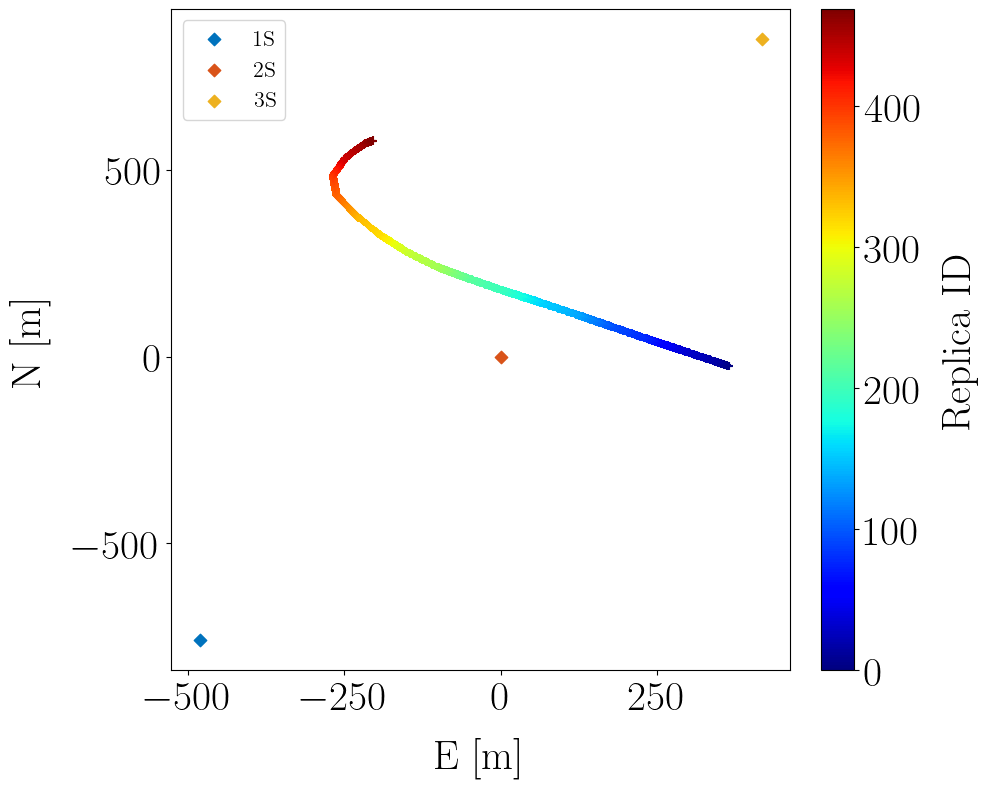

In [9]:
root_fig = os.path.join(sensibility_img_folder, "passive", f"library_{id_library}")
if not os.path.exists(root_fig):
    os.makedirs(root_fig)

plot_passive_positions(ds_replica=ds, ds_gps=ds_gps, root_fig=root_fig)

In [10]:
# Select frequency range
fmin = 5
fmax = 900
# Slice frequency
ds = ds.sel(f_rtf=slice(fmin, fmax))

freq = ds.f_rtf.values

# Build complex RTFs
rtf_cs_evd = ds.rtf_amp * np.exp(1j * ds.rtf_phase)


In [11]:
fig_folder = root_fig

In [12]:
fpath = r"C:\Users\baptiste.menetrier\Desktop\devPy\phd\real_data_analysis\fiberscope_groix\data\sequences\passive\sequence_passive_2025-10-15_10-14-00_to_2025-10-15_10-18-00_rtf.nc"
ds_sig = xr.open_dataset(fpath)
ds_sig

<xarray.Dataset> Size: 193MB
Dimensions:        (h_index: 3, time: 480000, f_rtf: 4097, segment_dt: 470,
                    f_csdm: 4097, h_index_bis: 3)
Coordinates:
  * h_index        (h_index) int64 24B 1 2 3
  * time           (time) float32 2MB 0.0 0.0005 0.001 ... 240.0 240.0 240.0
  * f_rtf          (f_rtf) float32 16kB 0.0 0.2441 0.4883 ... 999.5 999.8 1e+03
  * segment_dt     (segment_dt) datetime64[ns] 4kB 2025-10-15T10:14:02 ... 20...
  * f_csdm         (f_csdm) float32 16kB 0.0 0.2441 0.4883 ... 999.5 999.8 1e+03
  * h_index_bis    (h_index_bis) int64 24B 1 2 3
Data variables:
    signal         (h_index, time) float32 6MB ...
    start_dt       datetime64[ns] 8B ...
    end_dt         datetime64[ns] 8B ...
    rtf_amp_hat    (h_index, f_rtf, segment_dt) float32 23MB ...
    rtf_phase_hat  (h_index, f_rtf, segment_dt) float32 23MB ...
    Rx             (f_csdm, h_index, h_index_bis, segment_dt) float32 69MB ...
    Rv             (f_csdm, h_index, h_index_bis, segment_dt) float32 69MB ...
Attributes:
    fs:                              2000
    ts:                              0.0005
    datetime_format:                 %Y-%m-%d_%H-%M-%S
    record_id:                       passive_2025-10-15_10-14-00_to_2025-10-1...
    root_img:                        C:\Users\baptiste.menetrier\Desktop\devP...
    root_data:                       C:\Users\baptiste.menetrier\Desktop\devP...
    h_index_ref:                     2
    analysis_segment_duration:       5
    analysis_segment_alpha_overlap:  0.9

## Visualisation des signaux 

In [13]:
# Load wav data and plot the corresponding sequence
ds_wav = xr.open_dataset(os.path.join(data_folder, "channel_H_wav.nc"))


In [14]:
start_dt = passive_replicas_args["start_datetimes"][0]
ds_sig.attrs["start_datetime"] = start_dt.strftime(ds_sig.datetime_format)
ds_sig.attrs

{'fs': np.int64(2000),
 'ts': np.float64(0.0005),
 'datetime_format': '%Y-%m-%d_%H-%M-%S',
 'record_id': 'passive_2025-10-15_10-14-00_to_2025-10-15_10-18-00',
 'root_img': 'C:\\Users\\baptiste.menetrier\\Desktop\\devPy\\phd\\real_data_analysis\\fiberscope_groix\\img\\sequences\\passive_2025-10-15_10-14-00_to_2025-10-15_10-18-00',
 'root_data': 'C:\\Users\\baptiste.menetrier\\Desktop\\devPy\\phd\\real_data_analysis\\fiberscope_groix\\data\\sequences\\passive',
 'h_index_ref': np.int64(2),
 'analysis_segment_duration': np.int64(5),
 'analysis_segment_alpha_overlap': np.float64(0.9),
 'start_datetime': '2025-10-15_10-14-00'}

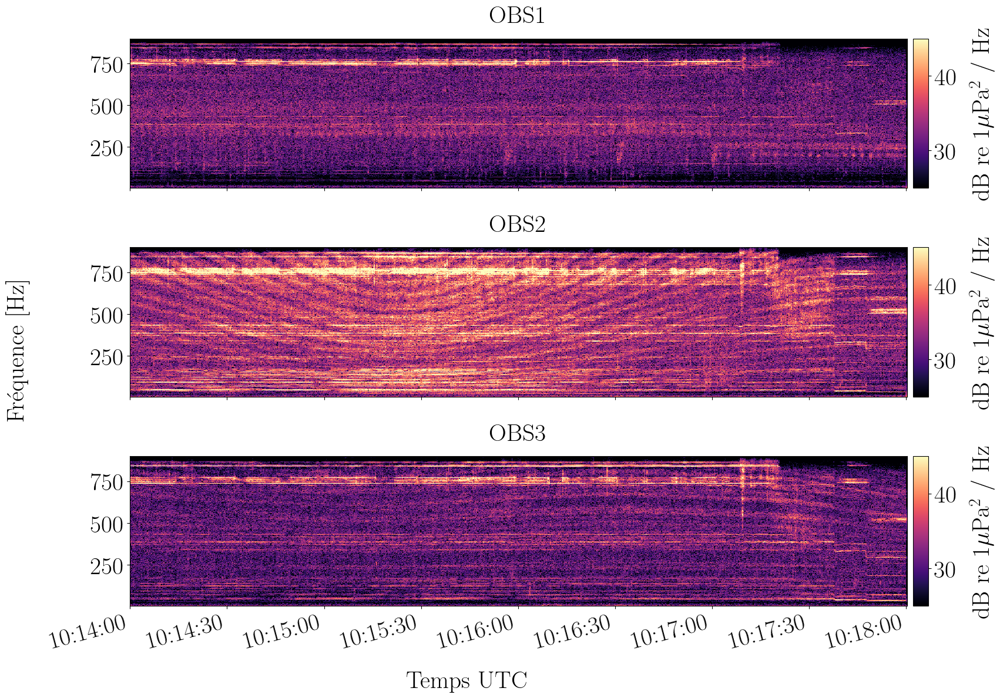

In [15]:
plot_sequence_spectrogram(ds_sig, ds_wav, fig_folder, nperseg=2**10, noverlap=2**9, fmin=fmin, fmax=fmax)

# Étape 2 : étude de la grandeur signante 

## Variations du module de $\Pi$ dans le plan (f, r)


On s'intéresse aux variations de $\lvert \Pi \rvert$ dans le plan (f, numéro de réplique). Ici, les hydrophones sont quasiment alignés, si l'on néglige les variations de vitesse du porteur et que l'on suppose donc que la source se déplace en ligne droite à vitesse constante, les variations dans le plan (f, numéro de réplique) sont équivalentes aux variations dans le plan (f, r). 

In [16]:
dist_rcv = get_dist_to_rcv(ds)
obs_cpa_idx = np.argmin(dist_rcv, axis=1).flatten()
reps = ds.replica_id.values

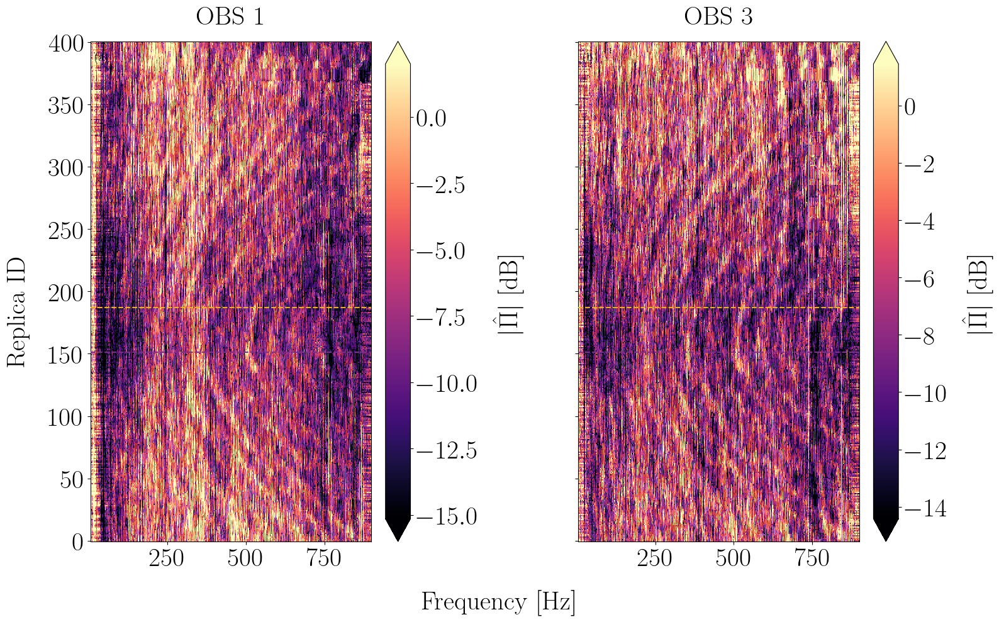

In [17]:
plot_rtf_mod_along_sequence(
    ds,
    dist_rcv,
    obs_cpa_idx,
    reps,
    fig_folder,
    replica_id_slice=slice(0, 400),
    fmin=fmin,
    fmax=fmax,
)

Cette représentation permet d'observer un certain nombre de structures qui évoluent dans le plan (f, r). Au vu des premières analyses menées en simulation, on peut supposer que ces figures résultent de la combinaison des franges d'interférences dans le plan (f, r) observées pour les différents couples de récepteurs. 

Cette visualisation est a priori encourageante pour la localisation et semble traduire une certaine continuité de la grandeur mesurée d'une position à une autre. Dit autrement, au vu de ces premiers résultats on peut espérer définir une métrique de similarité qui varie plus lentement au cours de la trajectoire de la source que la simple mesure de $\theta$ utilisée jusqu'ici. 

On peut clairement voir l'influence du SNR sur l'erreur d'estimation avec un bruit plus important en dessous de 300 Hz. 


## Étude des distributions  

Dans ce notebook, on se propose d'explorer l'utilisation de distribution des modules afin de caractériser chacune des positions. L'idée est la suivante : 

* Pour une réplique donnée, le module de chaque composante $\lvert \Pi_i(f) \rvert = \lvert  \frac{H_i}{H_{ref}} \rvert $ est vu comme un signal au sens où il représente une suite d'échantillons (en fonction de f). On peut ainsi calculer la distribution de valeurs de cette quantité (i.e l'histogramme normalisé de sorte que l'intégrale vaut 1). 
* La distance entre deux répliques peut alors être évaluée à l'aide d'une métrique de distance entre distributions statistiques. Il existe une multitude de métriques de ce type dans la littérature, il s'agit dans un premier temps de tester la viabilité de l'approche avec quelques distances a priori simples à mettre en œuvre (I.e déjà implémentées et disponibles sur étagère).   

### A quoi ça ressemble ?

In [18]:
fmin = fmin
fmax = fmax
n_bins = 100
log_mod_hist, log_mod_kde, bin_centers = get_log_module_distributions(
    ds, fmin=fmin, fmax=fmax, n_bins=n_bins
)

#### Histogramme 

In [19]:
idx_rep_ref = 100
distance_dict_hist = get_distribution_distance_all_rcv(
    log_mod_distribution=log_mod_hist,
    idx_rep_ref=idx_rep_ref,
    distances=["wasserstein", "jensen_shannon", "shannon_entropy"],
)

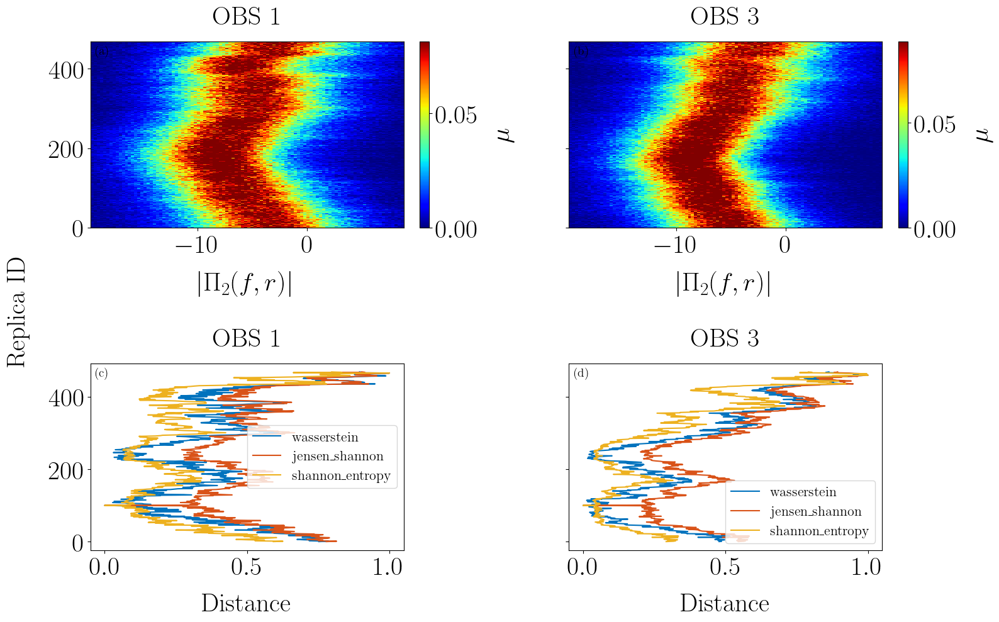

In [20]:
plot_log_mod_distribution_along_sequence(log_mod_hist, distance_dict_hist, bin_centers=bin_centers, replica_ids=ds.replica_id.values)

L'étude des distributions est encourageante. L'utilisation des distributions conduit à la perte d'une partie de l'information, en particulier l'ordonnancement des échantillons est perdue. Malgré cela, les distributions semblent évoluer de manière significative au cours de la trajectoire de la source. 

L'évolution de la moyenne de la distribution traduit a priori simplement l'évolution des pertes moyennes dans la bande considérée, la forme de la distribution doit encoder la spécificité du rapport de fonctions de transfert. 

La distance de Jensen-Shanon (JS) semble être davantage adaptée ici avec des variations significatives autour de la position de référence. Un point important est à noter, contrairement à la distance $\theta$, la distance JS ne présente pas de minimum au passage des CPAs des OBS.   

#### Gaussian KDE 

Au vu des distributions observées on peut estimer une densité de probabilité par application d'un noyau gaussien (qui performent a priori mieux sur les distributions unimodale). 

In [21]:
distance_dict_kde = get_distribution_distance_all_rcv(
    log_mod_distribution=log_mod_kde,
    idx_rep_ref=idx_rep_ref,
    distances=["wasserstein", "jensen_shannon", "shannon_entropy"],
)

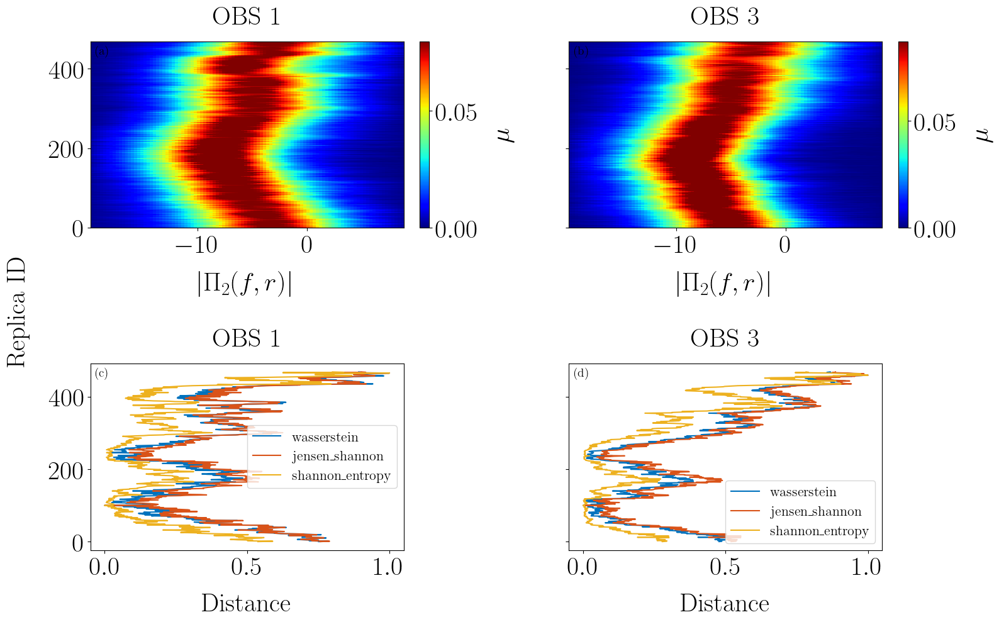

In [22]:
plot_log_mod_distribution_along_sequence(
    log_mod_kde,
    distance_dict_kde,
    bin_centers=bin_centers,
    replica_ids=ds.replica_id.values,
)

L'estimation de la densité de probabilité via un noyau gaussien conduit à un résultat très similaire. 

## Comparaison de plusieurs distances 

On se propose dans un premier temps de comparer les performances de différentes distances entre distributions : 

* Distance Jensen-Shanon
* Distance de Wasserstein 
* Divergence de Kullback-Liebler
* Entropie relative de Shannon 


### Distance sur les histogrammes 

In [23]:
idx_rep_ref = 25
distance_dict_hist = get_distribution_distance_all_rcv(
    log_mod_distribution=log_mod_hist,
    idx_rep_ref=idx_rep_ref,
    distances=["wasserstein", "jensen_shannon", "shannon_entropy"],
)

In [24]:
product_distance_dict_hist = get_combine_distance(
    distance_dict=distance_dict_hist, combine_method="product"
)
sum_distance_dict_hist = get_combine_distance(
    distance_dict=distance_dict_hist, combine_method="sum"
)

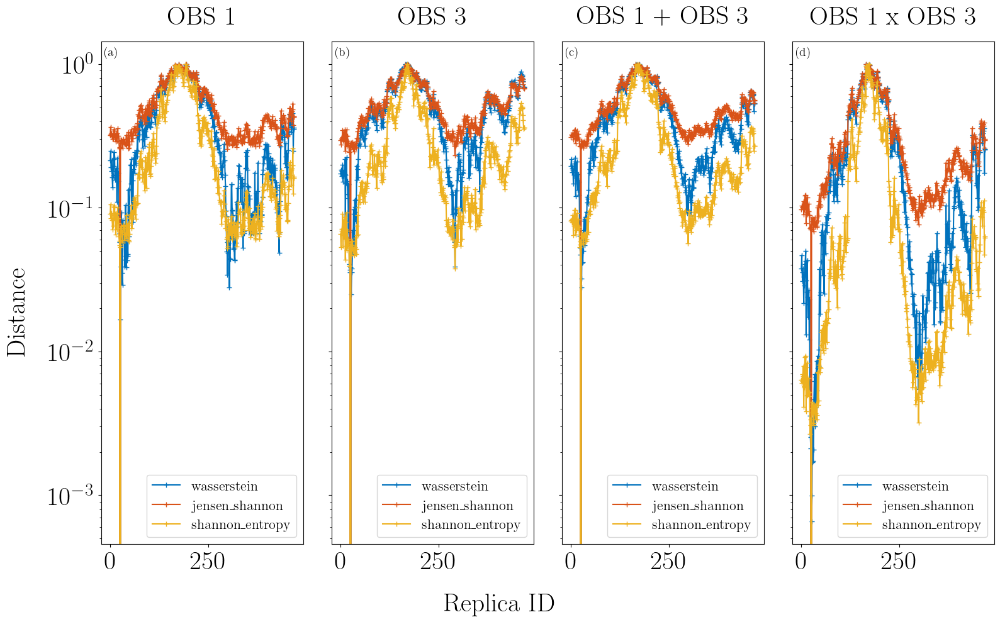

In [25]:
plot_dist_and_combined_dist(
    distance_dict_hist,
    product_distance_dict_hist,
    sum_distance_dict_hist,
    replica_ids=ds.replica_id.values,
)

La combinaison des distances associées à chacun des récepteurs permet d'obtenir des résultats intéressants. Les meilleurs résultats sont obtenus pour l'entropie relative de Shannon en sommant les distances associées à chaque récepteur.

### Distance sur les distributions après KDE 

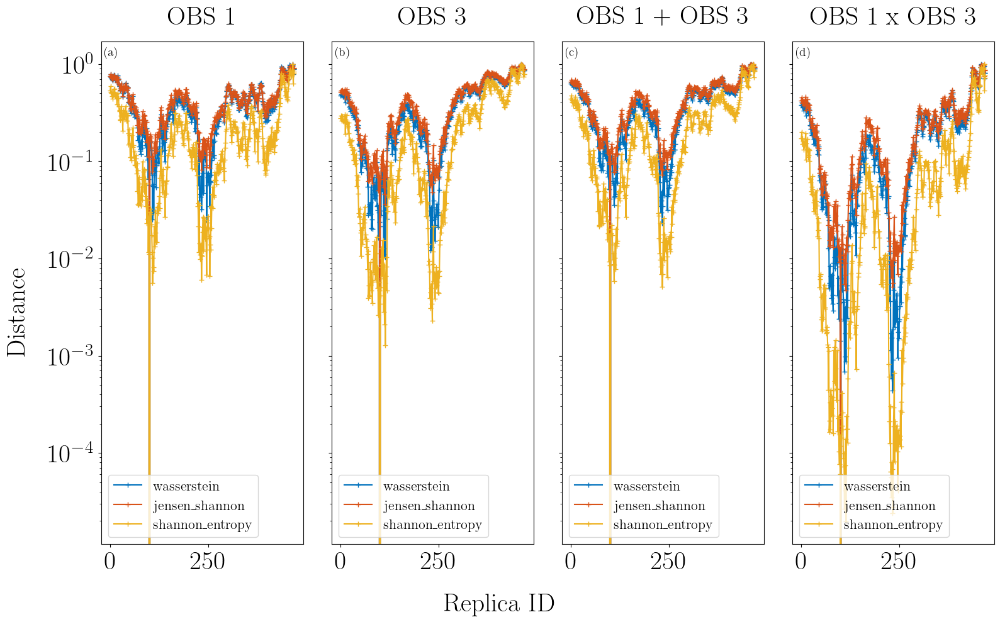

In [26]:
product_distance_dict_kde = get_combine_distance(
    distance_dict=distance_dict_kde, combine_method="product"
)
sum_distance_dict_kde = get_combine_distance(
    distance_dict=distance_dict_kde, combine_method="sum"
)
plot_dist_and_combined_dist(
    distance_dict_kde,
    product_distance_dict_kde,
    sum_distance_dict_kde,
    replica_ids=ds.replica_id.values,
)

## Validation par bootstrap

Afin de généraliser l'analyse faite sur quelques répliques de référence ci-dessus on calcule la matrice de bootstrap $M_S$ associée à l'entropie relative de Shannon combinée utilisée précédemment. 

Cette matrice est définie par : 

$$
    M_{S} = \begin{bmatrix}
        m_{ij}
    \end{bmatrix}_{(i, j) \in [0, {N_{rep}}]}, \quad \text{avec} \quad m_{ij} = \sum_{k=1, k\neq k_{ref}}^{N_{rcv}} S \left ( \mu_i^{(k)}, \mu_j^{(k)} \right ),
$$

où $\mu_i^{(k)}$ est la distribution du module $\lvert \frac{H_k}{H_{ref}} \rvert$ associé à la réplique $i$.


In [27]:
dist_rcv = get_dist_to_rcv(ds=ds)

In [28]:
spatial_dist_mat = build_dist_matrix(ds)

In [29]:
fmin = fmin
fmax = fmax
n_bins=100
input="histogram"
distances=["wasserstein", "jensen_shannon", "shannon_entropy"]

dist_mat_prod, dist_mat_sum = get_bootstrap_dist_matrix(
    ds,
    distances=distances,
    input=input,
    fmin=fmin,
    fmax=fmax,
    n_bins=n_bins,
)

### Distance de Wasserstein

#### Combinaison produit 

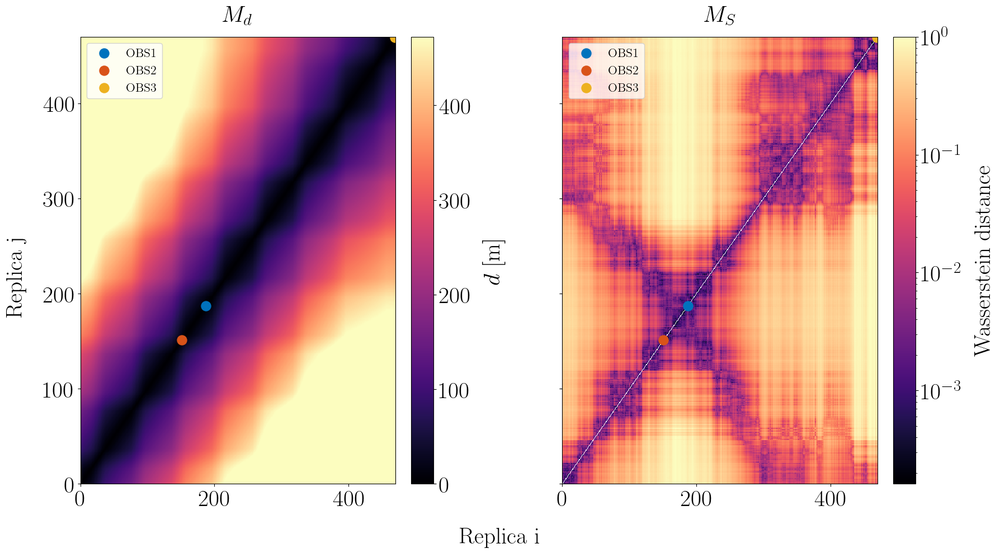

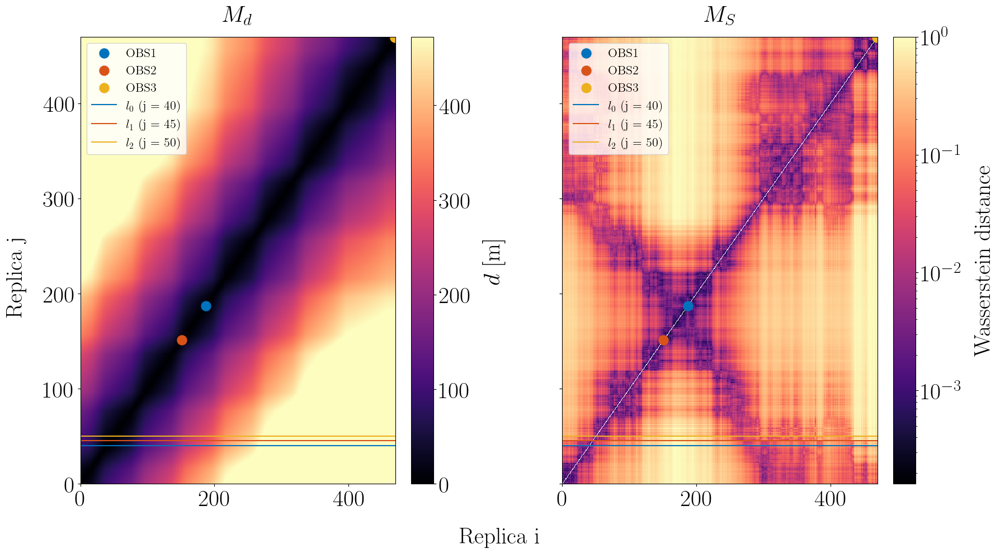

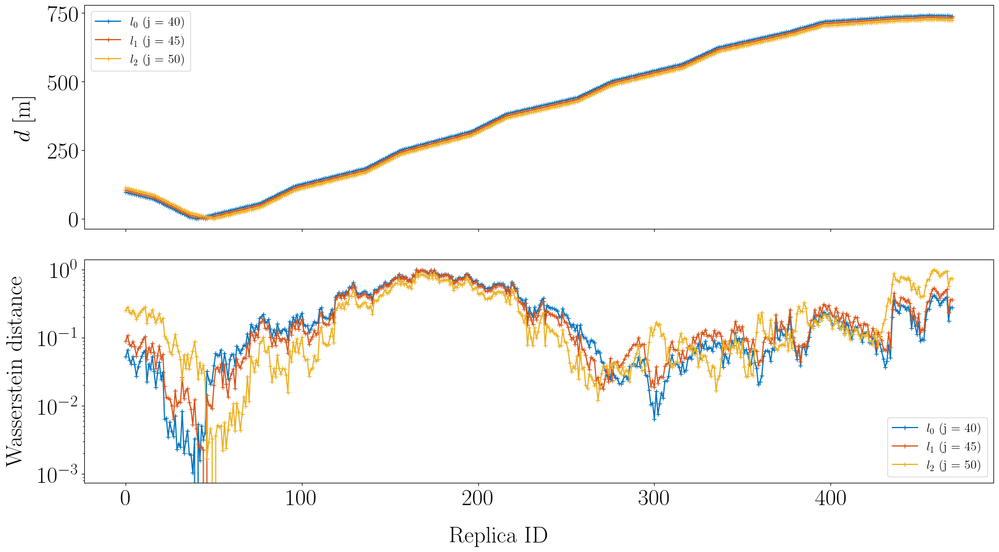

In [30]:
scale = "log"
distance = "wasserstein"
rcv_combinaison_strategy = "product"

plot_distance_matrix_comparison(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    scale=scale,
)
selected_lines = [40, 45, 50]
plot_distance_matrix_comparison_line_selected(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    selected_lines=selected_lines,
    scale=scale,
)
plot_distance_selected_lines(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    selected_lines=selected_lines,
    scale=scale,
)

#### Combinaison somme

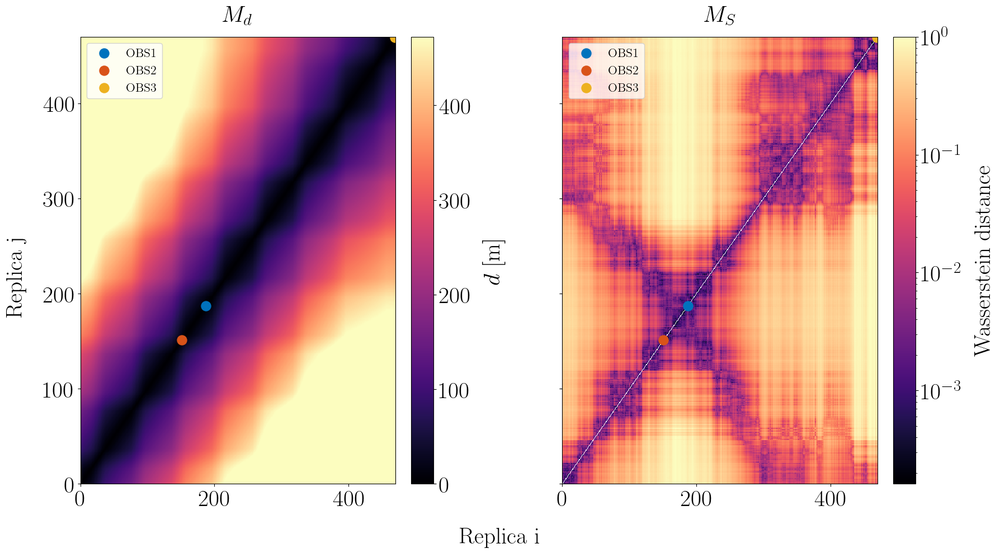

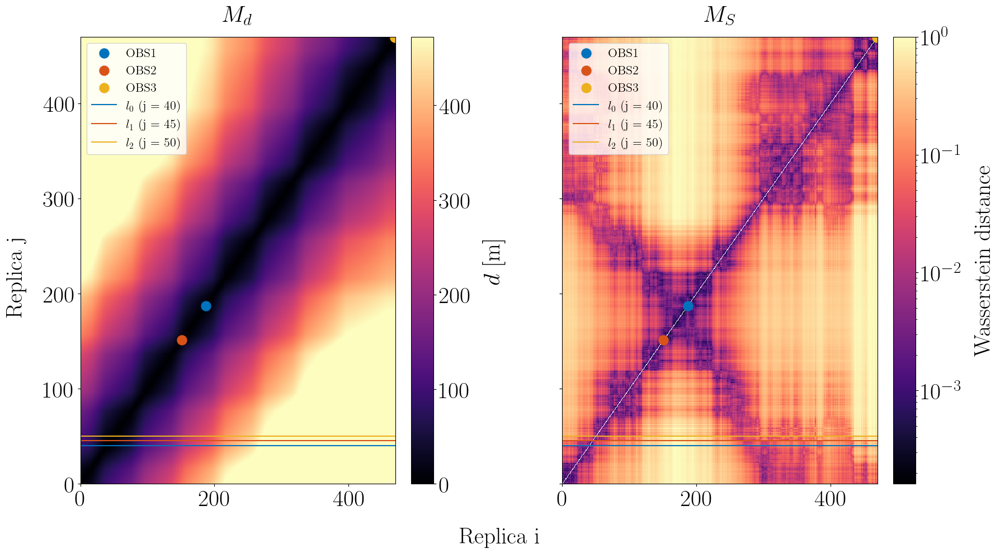

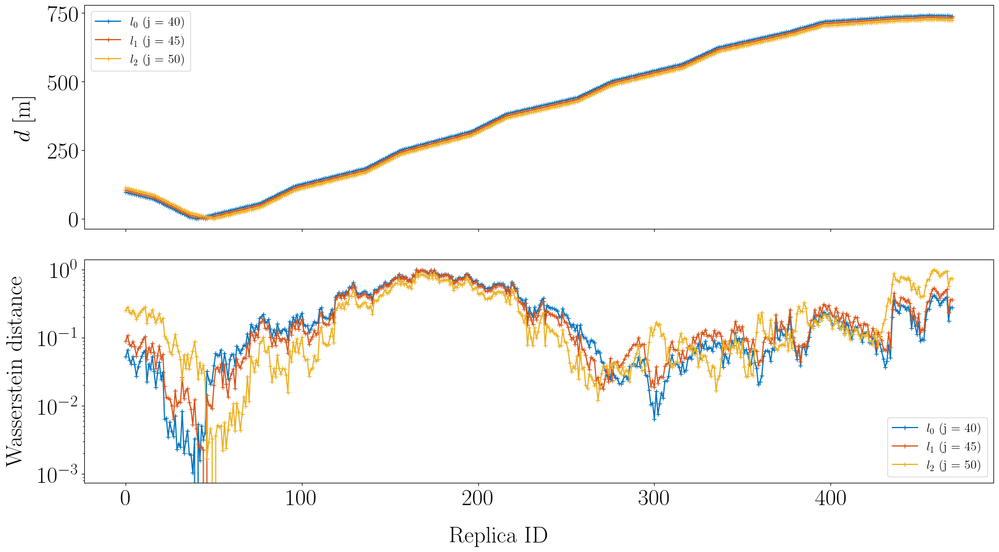

In [31]:
rcv_combinaison_strategy = "sum"

plot_distance_matrix_comparison(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    scale=scale,
)
selected_lines = [40, 45, 50]
plot_distance_matrix_comparison_line_selected(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    selected_lines=selected_lines,
    scale=scale,
)
plot_distance_selected_lines(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    selected_lines=selected_lines,
    scale=scale,
)

### Distance de Jensen-Shannon

#### Combinaison produit 

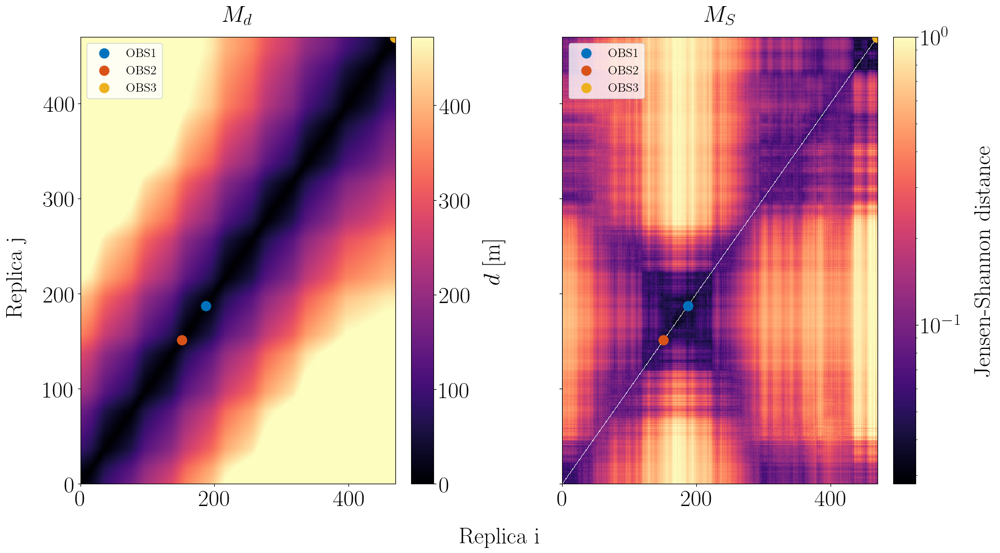

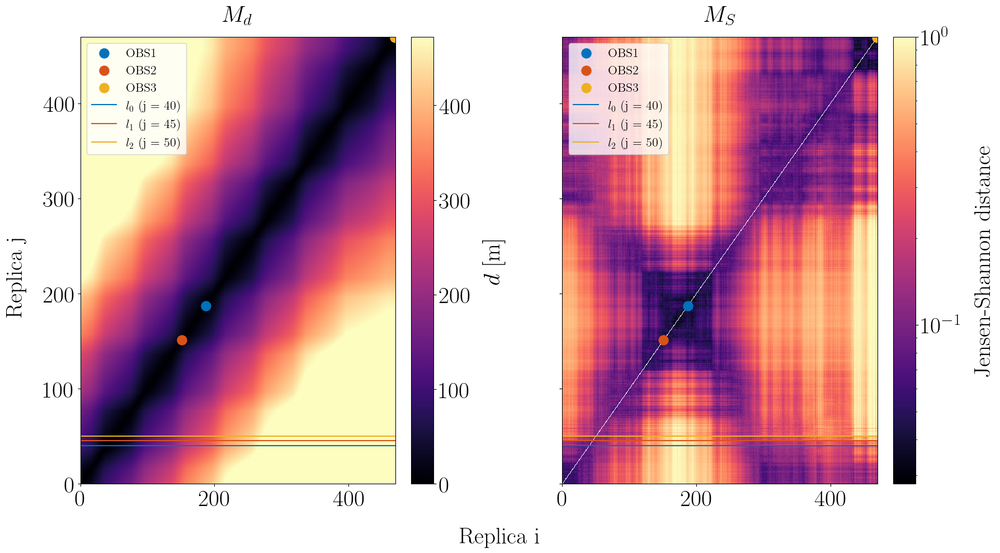

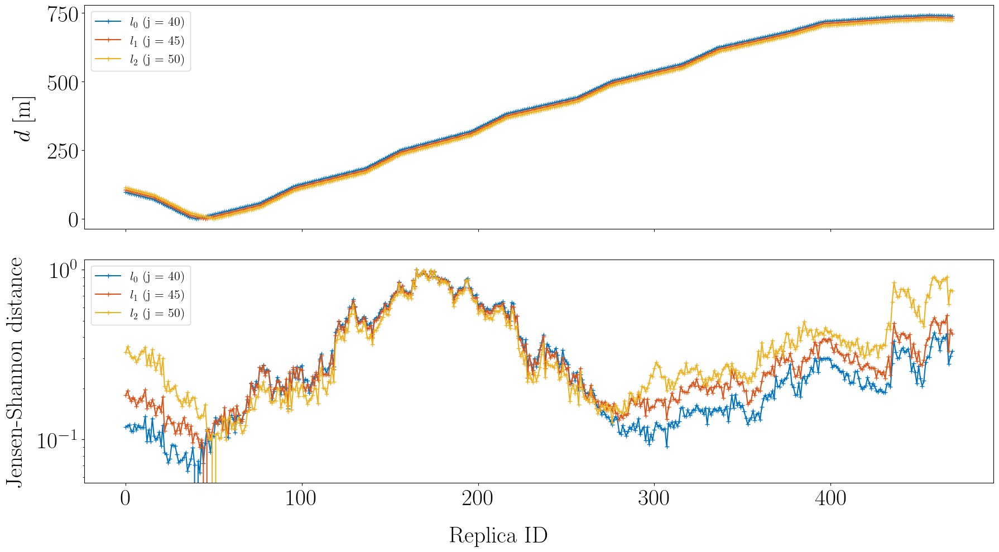

In [32]:
scale="log"
distance = "jensen_shannon"
rcv_combinaison_strategy = "product"

plot_distance_matrix_comparison(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    scale=scale,
)
selected_lines = [40, 45, 50]
plot_distance_matrix_comparison_line_selected(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    selected_lines=selected_lines,
    scale=scale,
)
plot_distance_selected_lines(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    selected_lines=selected_lines,
    scale=scale,
)

#### Combinaison somme

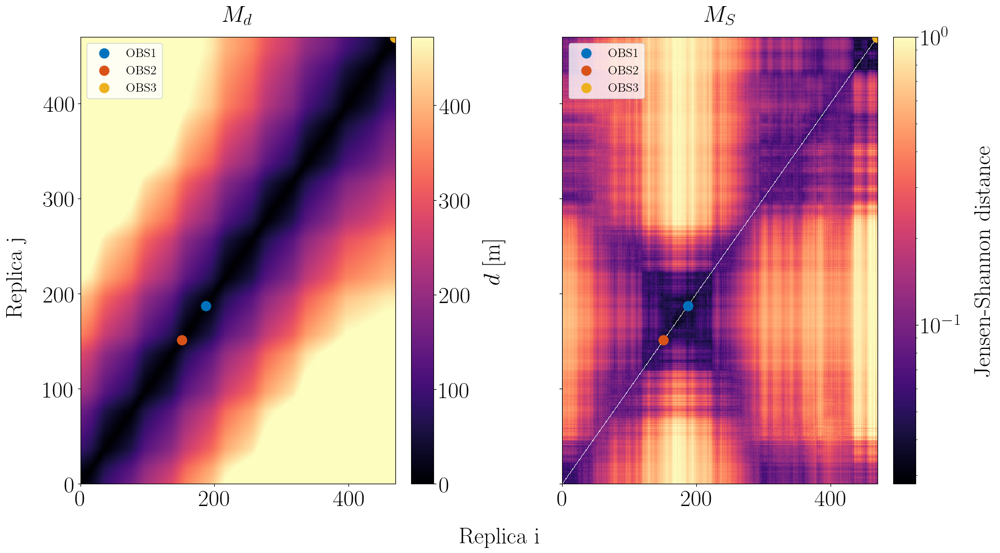

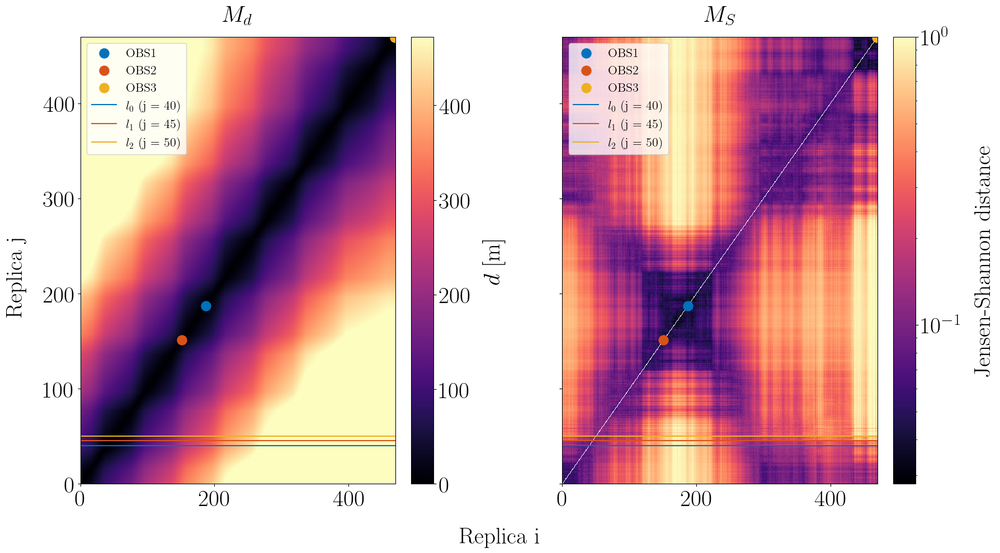

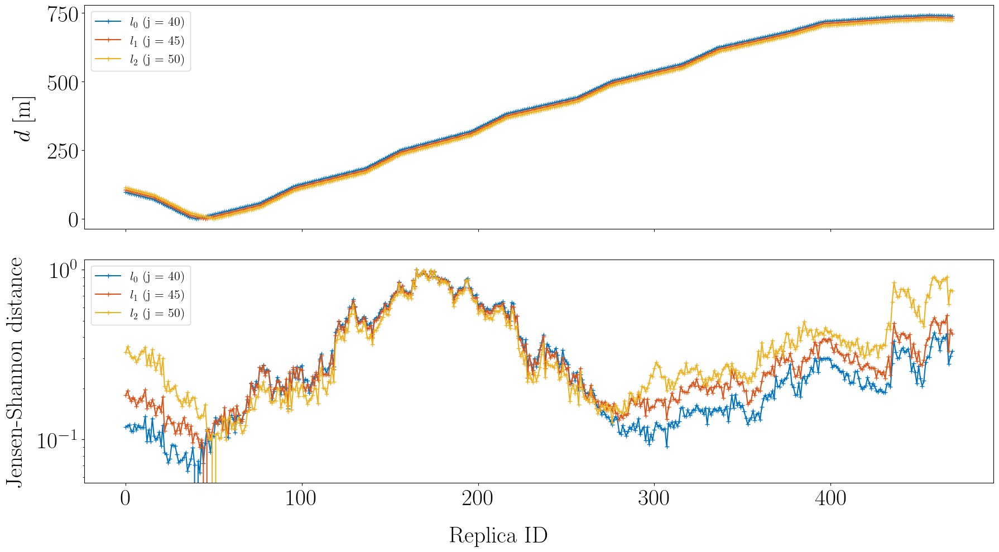

In [33]:
rcv_combinaison_strategy = "sum"

plot_distance_matrix_comparison(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    scale=scale,
)
selected_lines = [40, 45, 50]
plot_distance_matrix_comparison_line_selected(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    selected_lines=selected_lines,
    scale=scale,
)
plot_distance_selected_lines(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    selected_lines=selected_lines,
    scale=scale,
)

### Entropie de Shannon

#### Combinaison produit 

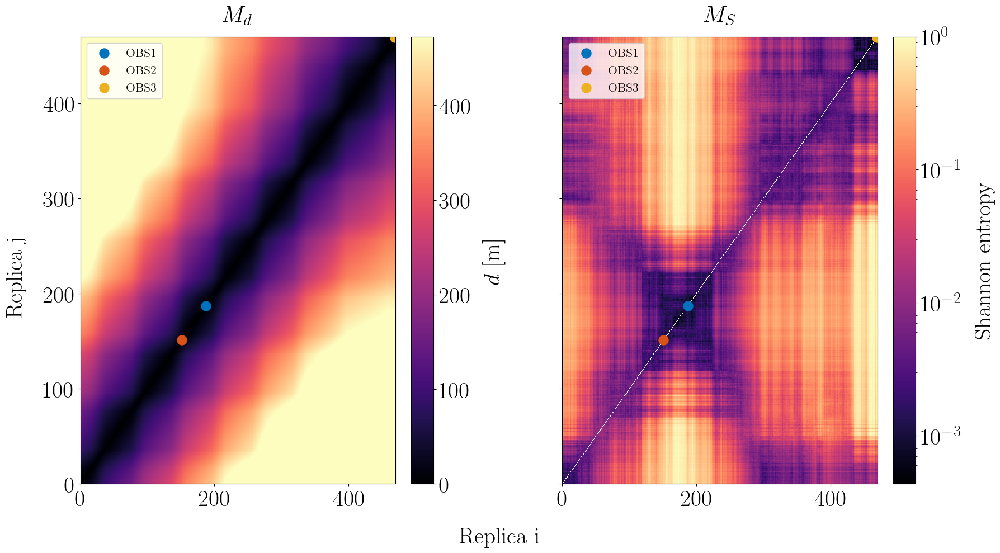

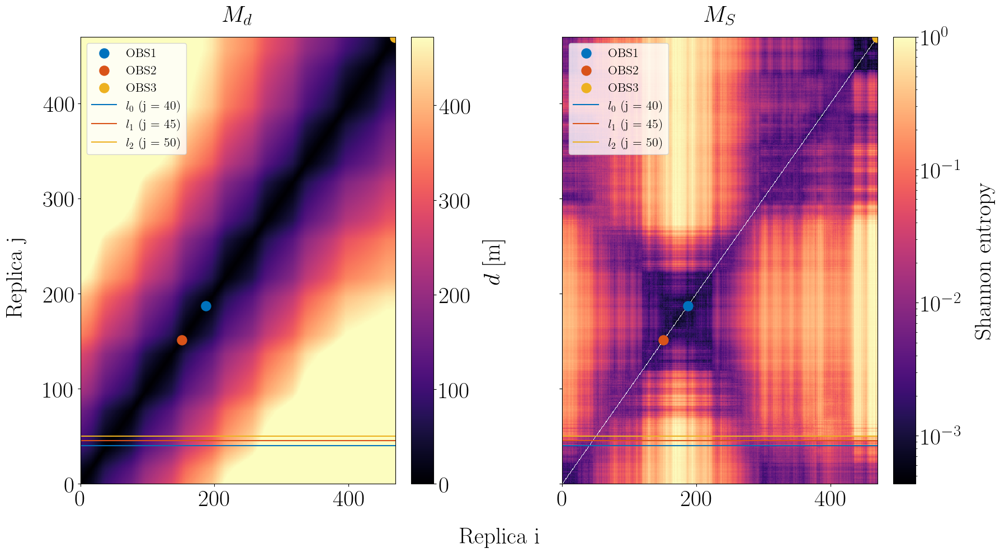

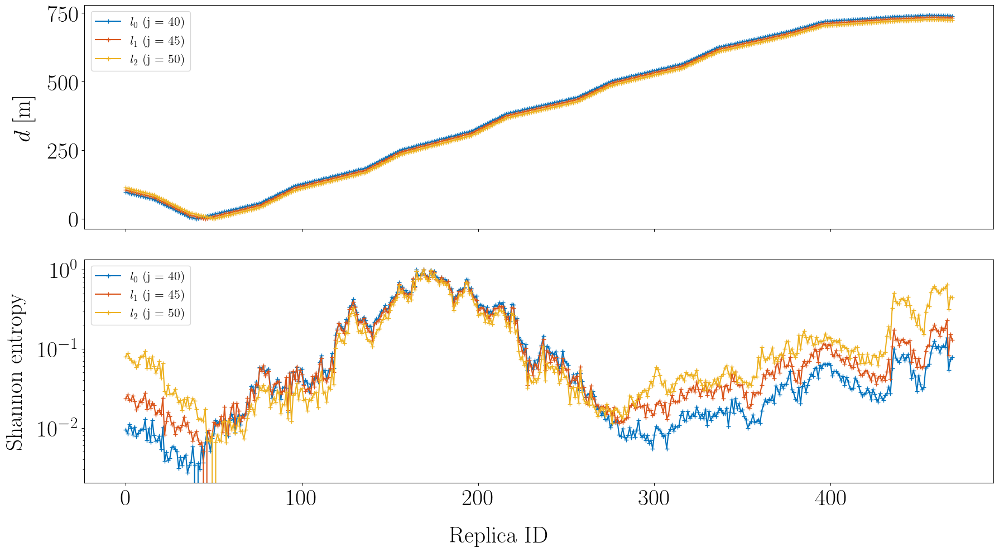

In [34]:
scale="log"
distance = "shannon_entropy"
rcv_combinaison_strategy = "product"

plot_distance_matrix_comparison(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    scale=scale,
)
selected_lines = [40, 45, 50]
plot_distance_matrix_comparison_line_selected(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    selected_lines=selected_lines,
    scale=scale,
)
plot_distance_selected_lines(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    selected_lines=selected_lines,
    scale=scale,
)

#### Combinaison somme

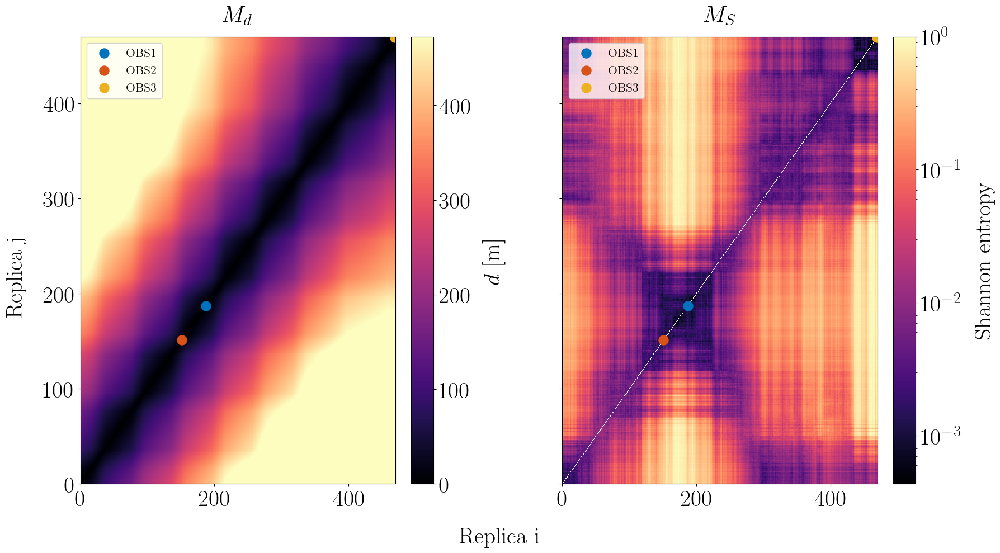

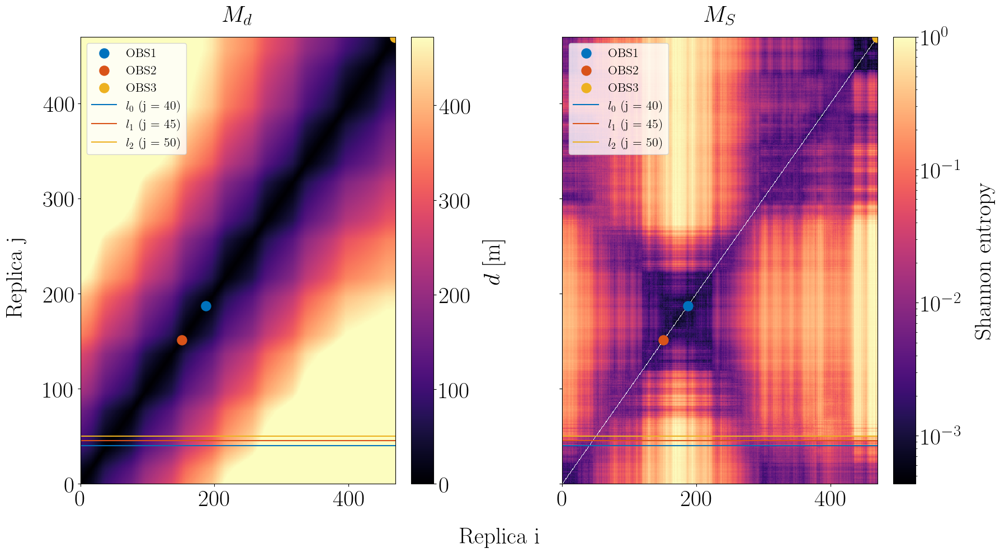

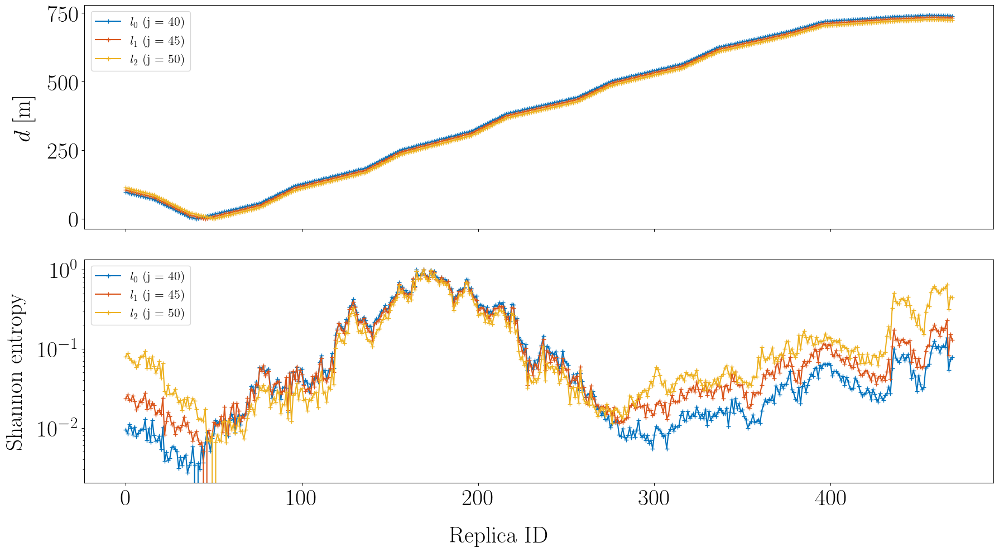

In [35]:
rcv_combinaison_strategy = "sum"

plot_distance_matrix_comparison(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    scale=scale,
)
selected_lines = [40, 45, 50]
plot_distance_matrix_comparison_line_selected(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    selected_lines=selected_lines,
    scale=scale,
)
plot_distance_selected_lines(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    selected_lines=selected_lines,
    scale=scale,
)

### Bilan global du bootstrap 

Principales conclusions de l'analyse par bootstrap :

* Quelle que soit la distance utilisée les variations observées sont les mêmes. 
* Contrairement à la métrique $\theta$, on retrouve ici la structure diagonale d'intérêt. 
* La matrice présente néanmoins des lobes secondaires qui ne traduisent pas la proximité dans l'espace. Ces structures sont elliptiques (cercle, branche d'hyperbole) et pourraient faire penser aux branches d'hyperboles observées sur les TDOA. A COMPLETER 
* La boucle du navire est visible de manière distincte. 
* Ici, on semble traduire davantage les variations de niveaux moyen d'énergie dans la bande (qui se traduisent en des variations de la moyenne de la distribution) que les variations de la forme de la distribution en elle-même qui elle dépend de la forme des RTFs. Dit autrement, on doit probablement trouver le même résultat s'il l'on prend comme grandeur signante le niveau d'énergie moyen dans la bande associé à chaque pulse (...).


## Et dans une sous bande, ça donne quoi ? 



In [36]:
f_bw = 100   # bandwidth of the frequency range to consider around the reference frequency
fmin = ds.f_rtf.values.min()
fmax = fmin + f_bw
n_bins = 100     # Should be addapted to the selected bandwith, short bandwidth -> less bins, large bandwidth -> more bins


# Define a common min and max bin edge across all frequency bins to ensure comparability of the distributions
dist_min = np.percentile(10 * np.log10(ds.rtf_amp.values), 0.3)
dist_max = np.percentile(10 * np.log10(ds.rtf_amp.values), 99.7)
dist_min_max = (dist_min, dist_max)

min_freqs = []
max_freqs = []

i = 0
while fmin < ds.f_rtf.max():
    print(f"Processing frequency range {fmin:.1f} - {fmax:.1f} Hz")
    # Compute distributions for the current frequency range
    log_mod_hist, log_mod_kde, bin_centers = get_log_module_distributions(
        ds, fmin=fmin, fmax=fmax, n_bins=n_bins, dist_min_max=dist_min_max
    )

    if i == 0:
        dist_max_val = {id_rcv: [] for id_rcv in log_mod_hist.keys()}
        dist_max_pos = {id_rcv: [] for id_rcv in log_mod_hist.keys()}
        dist_q1_pos = {id_rcv: [] for id_rcv in log_mod_hist.keys()}
        dist_q2_pos = {id_rcv: [] for id_rcv in log_mod_hist.keys()}
        dist_q3_pos = {id_rcv: [] for id_rcv in log_mod_hist.keys()}

        i += 1

    # Extract caracteristics of the distributions
    dist = log_mod_kde  # or log_mod_kde
    for id_rcv in log_mod_hist.keys():
        # Extract the maximum of the distribution and its corresponding x value
        max_dist = np.max(dist[id_rcv], axis=1)
        idx_max = np.argmax(dist[id_rcv], axis=1)
        x_max = bin_centers[idx_max]    

        # Extract quantiles of the distribution and their corresponding x values
        q1 = np.percentile(dist[id_rcv], 25, axis=1)
        q2 = np.percentile(dist[id_rcv], 50, axis=1)
        q3 = np.percentile(dist[id_rcv], 75, axis=1)
        # # Get abcisse corresponding to the quantiles : x_q1, mu(x_q1) = q1, x_q2, mu(x_q2) = q2, x_q3, mu(x_q3) = q3
        # Q1
        dx_q1 = np.abs(dist[id_rcv] - q1[:, np.newaxis])  # (nb_replica, nbins)
        idx_xq1 = np.argmin(dx_q1, axis=1)
        x_q1 = bin_centers[idx_xq1]
        # Q2
        dx_q2 = np.abs(dist[id_rcv] - q2[:, np.newaxis])
        idx_xq2 = np.argmin(dx_q2, axis=1)
        x_q2 = bin_centers[idx_xq2]
        # Q3
        dx_q3 = np.abs(dist[id_rcv] - q3[:, np.newaxis])
        idx_xq3 = np.argmin(dx_q3, axis=1)
        x_q3 = bin_centers[idx_xq3]

        # Store
        dist_max_val[id_rcv].append(max_dist)
        dist_max_pos[id_rcv].append(x_max)
        dist_q1_pos[id_rcv].append(x_q1)
        dist_q2_pos[id_rcv].append(x_q2)
        dist_q3_pos[id_rcv].append(x_q3)

        # # Plot for debug
        # plt.figure()
        # plt.plot(bin_centers, log_mod_hist[id_rcv][10, :])
        # plt.plot(x_max[10], log_mod_hist[id_rcv][10, idx_max[10]], "ro", label="max")
        # plt.axvline(x_max[10], color="r", linestyle="--", label="max")
        # plt.axvline(x_q1[10], color="r", linestyle="--", label="Q1")
        # plt.axvline(x_q2[10], color="g", linestyle="--", label="Q2")
        # plt.axvline(x_q3[10], color="b", linestyle="--", label="Q3")
        # plt.savefig("test")

    # Update frequency range for the next iteration
    min_freqs.append(fmin)
    max_freqs.append(fmax)
    fmin += f_bw
    fmax += f_bw

# Convert lists to arrays
min_freqs = np.array(min_freqs)
max_freqs = np.array(max_freqs)

for id_rcv in log_mod_hist.keys():
    dist_max_val[id_rcv] = np.array(dist_max_val[id_rcv])
    dist_max_pos[id_rcv] = np.array(dist_max_pos[id_rcv])
    dist_q1_pos[id_rcv] = np.array(dist_q1_pos[id_rcv])
    dist_q2_pos[id_rcv] = np.array(dist_q2_pos[id_rcv])
    dist_q3_pos[id_rcv] = np.array(dist_q3_pos[id_rcv])

Processing frequency range 5.1 - 105.1 Hz
Processing frequency range 105.1 - 205.1 Hz
Processing frequency range 205.1 - 305.1 Hz
Processing frequency range 305.1 - 405.1 Hz
Processing frequency range 405.1 - 505.1 Hz
Processing frequency range 505.1 - 605.1 Hz
Processing frequency range 605.1 - 705.1 Hz
Processing frequency range 705.1 - 805.1 Hz
Processing frequency range 805.1 - 905.1 Hz


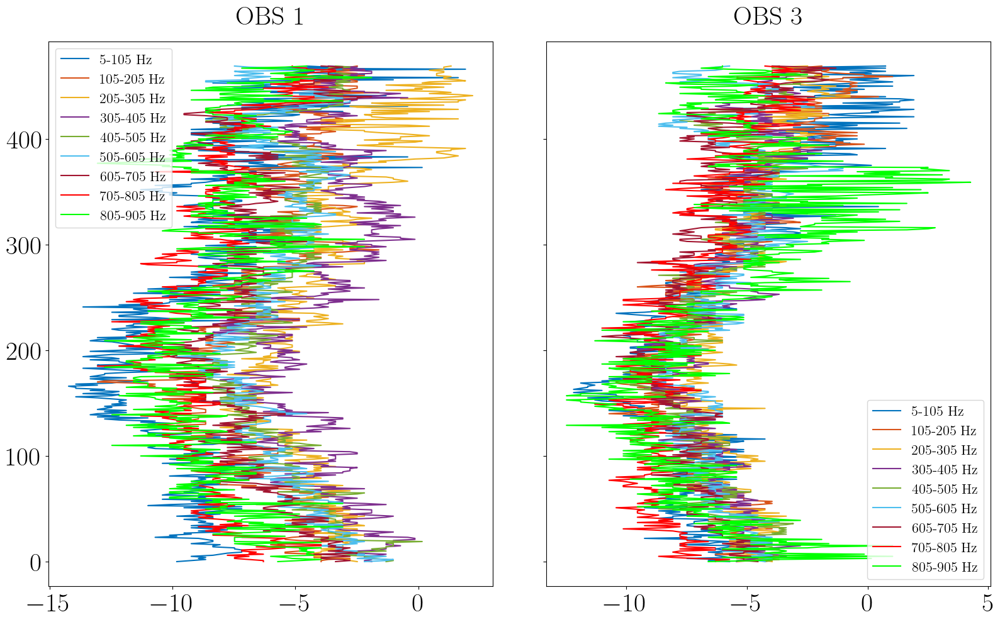

In [37]:
# Plot the evolution of caracteristics of the distribution along the sequence for each receiver
idx_rcv_plot = list(dist_q2_pos.keys())
fig, axs = plt.subplots(
    nrows=1, ncols=len(idx_rcv_plot), sharex=False, sharey="row", figsize=(16, 10)
)

i_ax = 0
for id_rcv in idx_rcv_plot:
    for i_f in range(min_freqs.size):
        min_f = min_freqs[i_f]
        max_f = max_freqs[i_f]
        axs[i_ax].plot(
            dist_max_pos[id_rcv][i_f, :],
            ds.replica_id.values,
            label=f"{min_f:.0f}-{max_f:.0f} Hz",
            color=color(i_f),
        )

    axs[i_ax].set_title(f"OBS {id_rcv}")
    axs[i_ax].legend()

    i_ax += 1

# plt.ylim([0, 100])

Ce n'est pas toujours facile d'interpréter néanmoins on peut observer une différence notable entre la distribution de la gamme la plus basse fréquence (200 - 300 Hz) et la gamme plus hautes fréquences (800, 900). Ces variations peuvent être dues à une plus forte atténuation à basse fréquence (peu de modes propagatifs et point source proche des 0 des fonctions modales) ou bien à une variation des performances de l'estimateur des RTFs plus importante dans cette gamme de fréquence en raison du plus faible niveau de la source (Cf réponse de la source). 

In [38]:
fmin = min_freqs[0]
fmax = max_freqs[0]
log_mod_hist, log_mod_kde, bin_centers = get_log_module_distributions(
    ds, fmin=fmin, fmax=fmax, n_bins=n_bins, dist_min_max=dist_min_max
)

In [39]:
idx_rep_ref = 25
distance_dict_hist = get_distribution_distance_all_rcv(
    log_mod_distribution=log_mod_hist,
    idx_rep_ref=idx_rep_ref,
    distances=["wasserstein", "jensen_shannon", "shannon_entropy"],
)

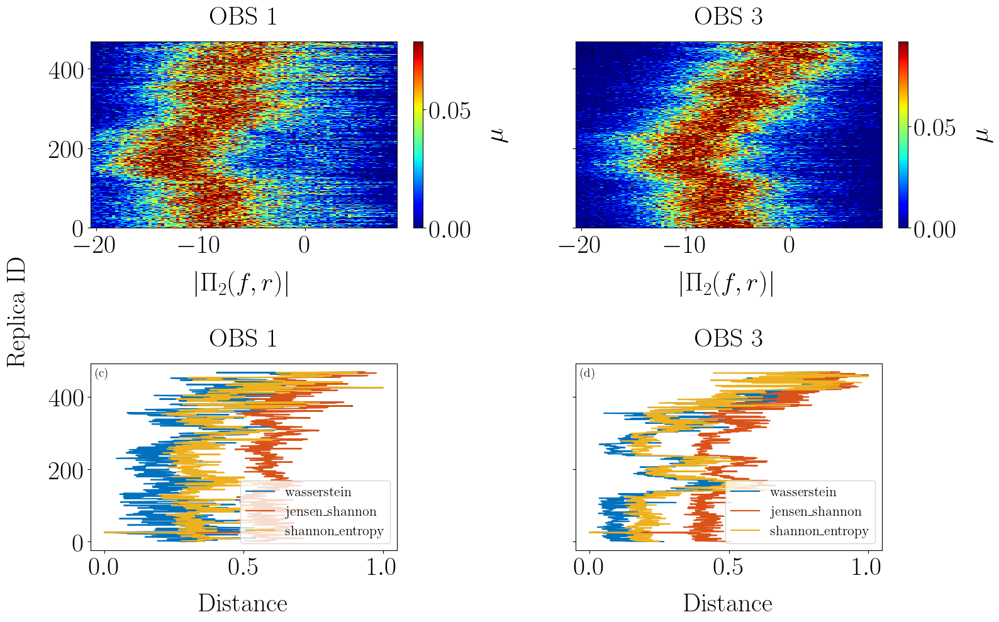

In [40]:
plot_log_mod_distribution_along_sequence(log_mod_hist, distance_dict_hist, bin_centers=bin_centers, replica_ids=ds.replica_id.values)

In [41]:
# distance_dict_kde = get_distribution_distance_all_rcv(
#     log_mod_distribution=log_mod_kde,
#     idx_rep_ref=idx_rep_ref,
#     distances=["wasserstein", "jensen_shannon", "shannon_entropy"],
# )

In [42]:
# plot_log_mod_distribution_along_sequence(
#     log_mod_kde,
#     distance_dict_kde,
#     bin_centers=bin_centers,
#     replica_ids=ds.replica_id.values,
# )

In [43]:
fmin = min_freqs[-2]
fmax = max_freqs[-2]
print(fmin, fmax)
log_mod_hist, log_mod_kde, bin_centers = get_log_module_distributions(
    ds, fmin=fmin, fmax=fmax, n_bins=n_bins, dist_min_max=dist_min_max
)

705.12695 805.12695


In [44]:
distance_dict_hist = get_distribution_distance_all_rcv(
    log_mod_distribution=log_mod_hist,
    idx_rep_ref=idx_rep_ref,
    distances=["wasserstein", "jensen_shannon", "shannon_entropy"],
)

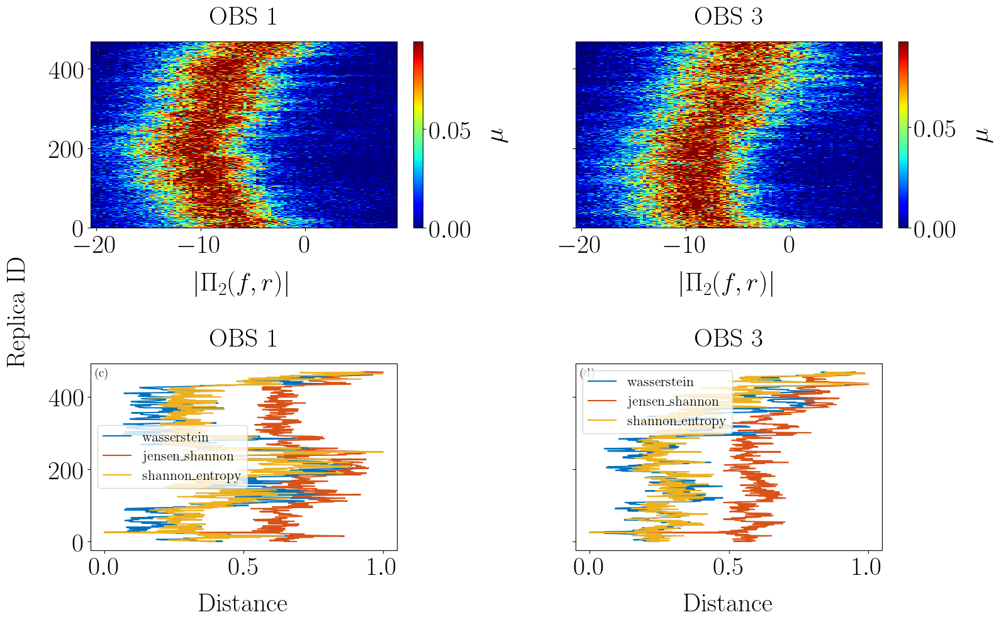

In [45]:
plot_log_mod_distribution_along_sequence(
    log_mod_hist,
    distance_dict_hist,
    bin_centers=bin_centers,
    replica_ids=ds.replica_id.values,
)

Les distributions ne sont pas semblables dans la bande 200 - 300 Hz et dans la bande 700 - 800 Hz. En effet, les distributions à BF semblent globalement unimodales avec une dispersion importante tandis que les distributions de la gamme HF ont une plus faible dispersion mais une distribution qui ne semble pas nécessairement unimodale. 

In [46]:
input="histogram"
distances=["wasserstein"]

fmin = min_freqs[0]
fmax = max_freqs[0]
print(fmin, fmax)

dist_mat_prod, dist_mat_sum = get_bootstrap_dist_matrix(
    ds,
    distances=distances,
    input=input,
    fmin=fmin,
    fmax=fmax,
    n_bins=n_bins,
)

5.126953 105.12695


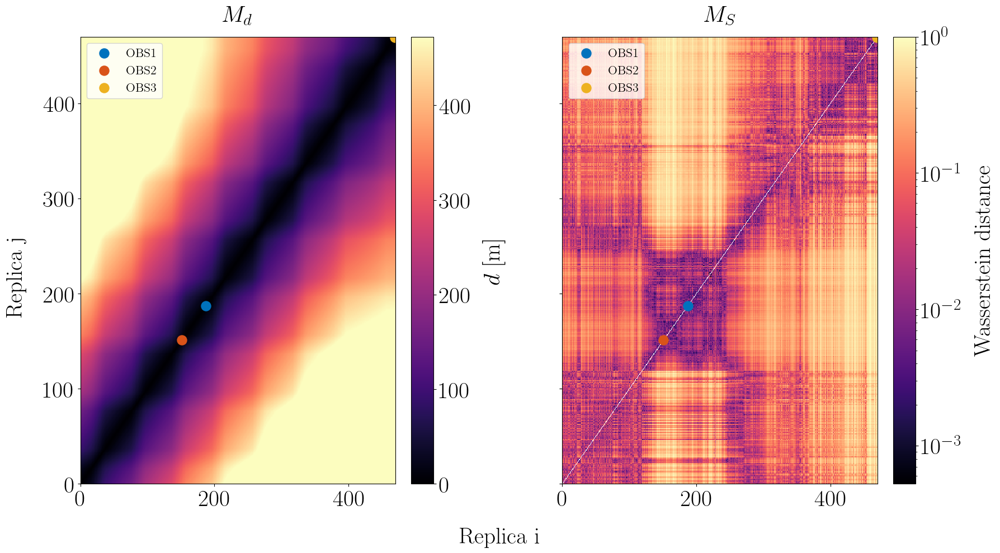

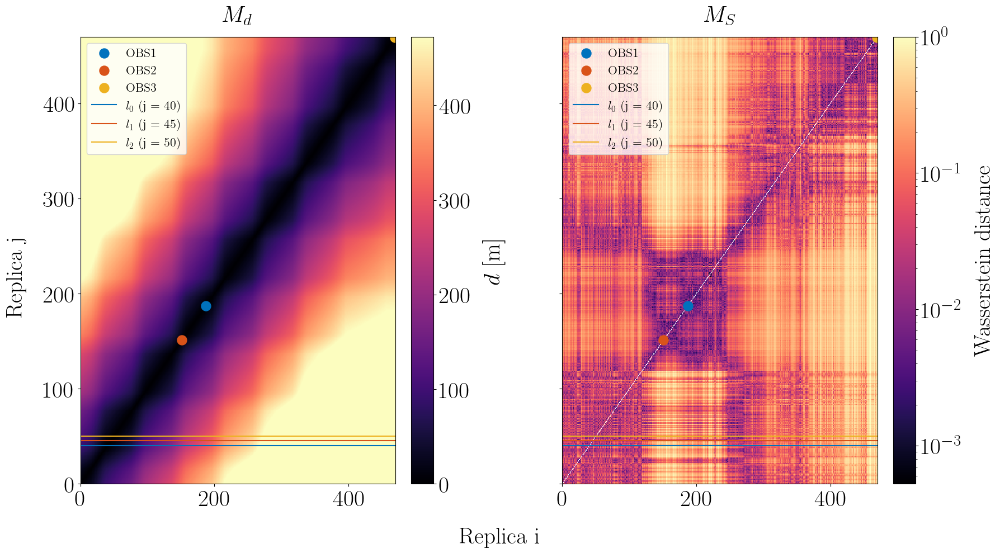

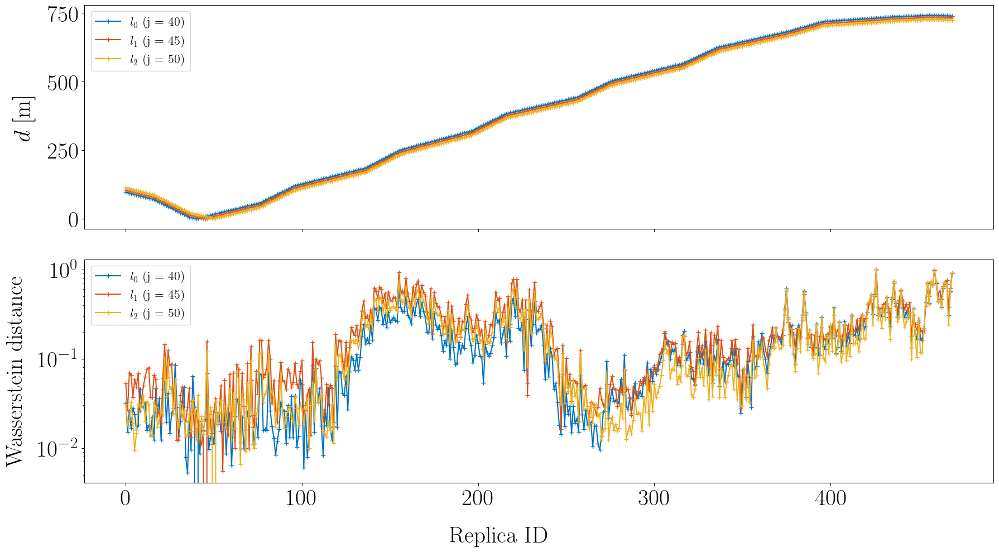

In [47]:
scale = "log"
distance = "wasserstein"
rcv_combinaison_strategy = "product"

plot_distance_matrix_comparison(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    scale=scale,
)
selected_lines = [40, 45, 50]
plot_distance_matrix_comparison_line_selected(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    selected_lines=selected_lines,
    scale=scale,
)
plot_distance_selected_lines(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    selected_lines=selected_lines,
    scale=scale,
)

In [48]:
input="histogram"
distances=["wasserstein"]

fmin = min_freqs[-1]
fmax = max_freqs[-1]
print(fmin, fmax)

dist_mat_prod, dist_mat_sum = get_bootstrap_dist_matrix(
    ds,
    distances=distances,
    input=input,
    fmin=fmin,
    fmax=fmax,
    n_bins=n_bins,
)

805.12695 905.12695


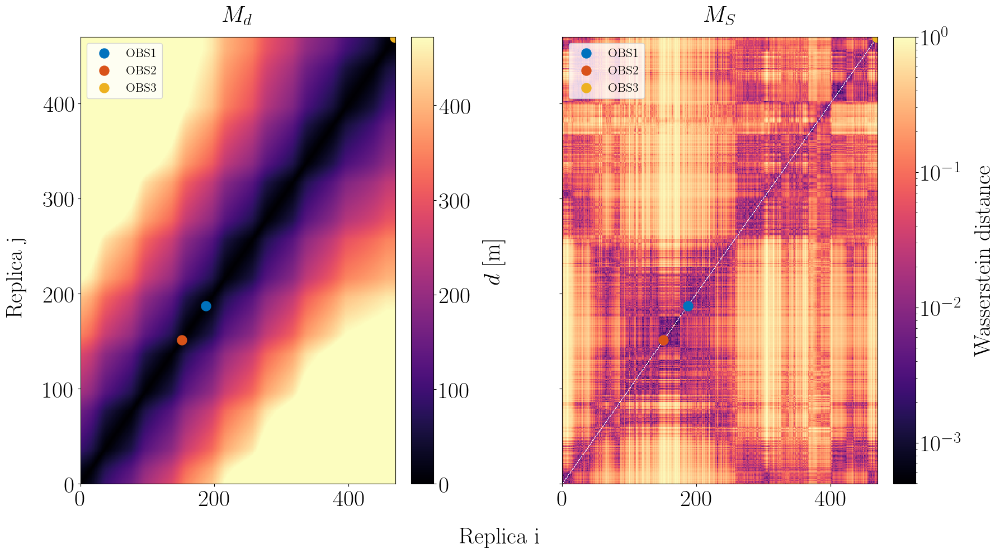

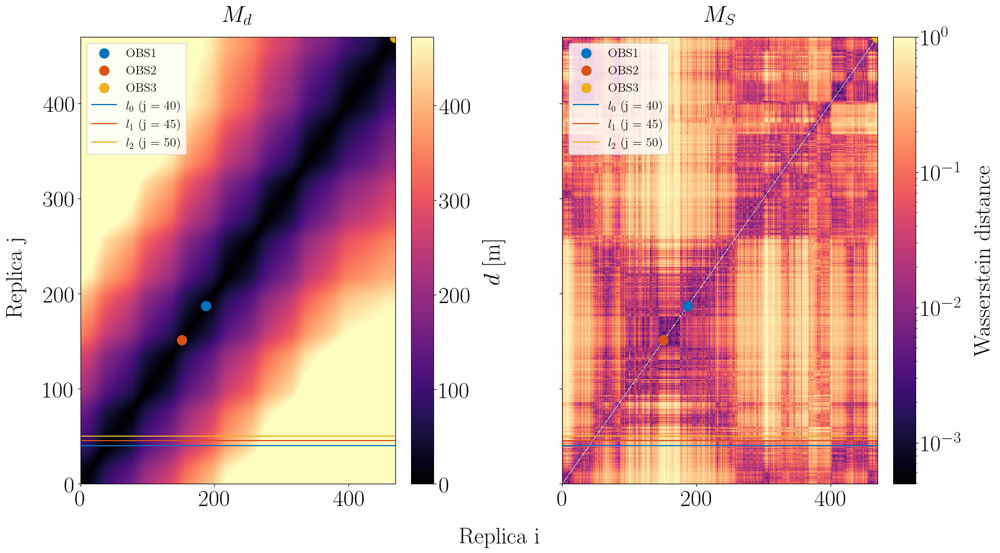

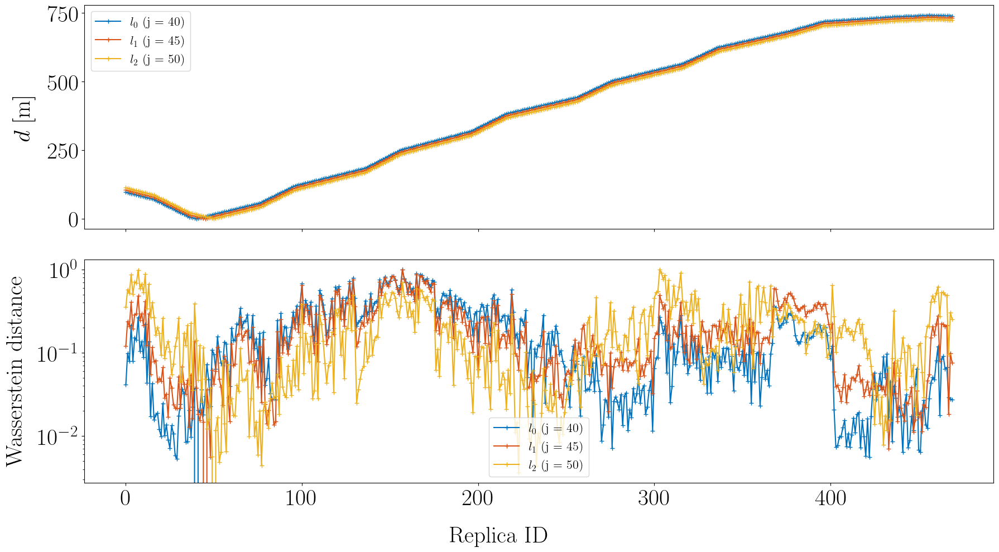

In [49]:
scale = "log"
distance = "wasserstein"
rcv_combinaison_strategy = "product"

plot_distance_matrix_comparison(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    scale=scale,
)
selected_lines = [40, 45, 50]
plot_distance_matrix_comparison_line_selected(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    selected_lines=selected_lines,
    scale=scale,
)
plot_distance_selected_lines(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_prod[distance],
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    selected_lines=selected_lines,
    scale=scale,
)

L'utilisation de sous bandes de fréquences conduit à des motifs légèrement différents et on peut espérer réduire le niveau des lobes secondaires en sommant sur différentes sous bande. Le gain potentiel semble tout de même très limité.  

## Distribution jointe des deux capteurs 

Afin d'exploiter au mieux l'information contenue dans l'ensemble des distributions observées (une par capteur différent du capteur de référence) on se propose de considérer la distribution jointe de ces N-1 capteurs (ici N = 3 et on a donc 2 distributions exploitables).    

On note  $\mu_{k, i}$ la distribution des valeurs de $\left \{ \log_{10} \left ( \left \lvert \frac{H_k}{H_{ref}} \right \rvert \right )(f),\quad f \in [f_{\text{min}}, f_{\text{max}}] \right \}$ associée à la réplique $i$.

Considérons deux capteurs $k$ et $q$ (différents du capteur de référence) et un numéro de réplique $i$ donné. Supposons que les distributions $\mu_{k, i}(x)$ et $\mu_{q, i}(y)$ soient indépendantes. 

*Remarque* : la notion d'indépendance de distributions de statistiques est à clarifier. Les deux distributions dépendent du même capteur de référence au dénominateur, cela viole-t-il l'hypothèse d'indépendance ? 

On peut définir la distribution jointe notée $\mu_{kq, i}$ :

$$ 
\mu_{kq, i}(x, y) = \mu_{k, i}(x) \mu_{q, i}(y)
$$

Cette distribution est donc une distribution 2D et on se propose ici d'étudier les distances entre répliques $i$ et $j$ ($i \neq j$) au moyen de la distance de Wassertein généralisée au cas de distributions multidimensionnelle. 

### Cas de deux distributions indépendantes 

In [50]:
n_bins = 100
fmin, fmax = fmin, fmax
log_mod_hist, log_mod_kde, bin_centers = get_log_module_distributions(
    ds, fmin=fmin, fmax=fmax, n_bins=n_bins,
)

idx_rcv = list(log_mod_hist.keys())
hist_0 = log_mod_hist[idx_rcv[0]]  # Distribution of first receiver
hist_1 = log_mod_hist[idx_rcv[1]]  # Distribution of second receiver
mu_0 = log_mod_kde[idx_rcv[0]]  # Distribution of first receiver
mu_1 = log_mod_kde[idx_rcv[1]]  # Distribution of second receiver

#### Allure pour une réplique i donnée 

Text(0, 0.5, '$\\mu (x)$')

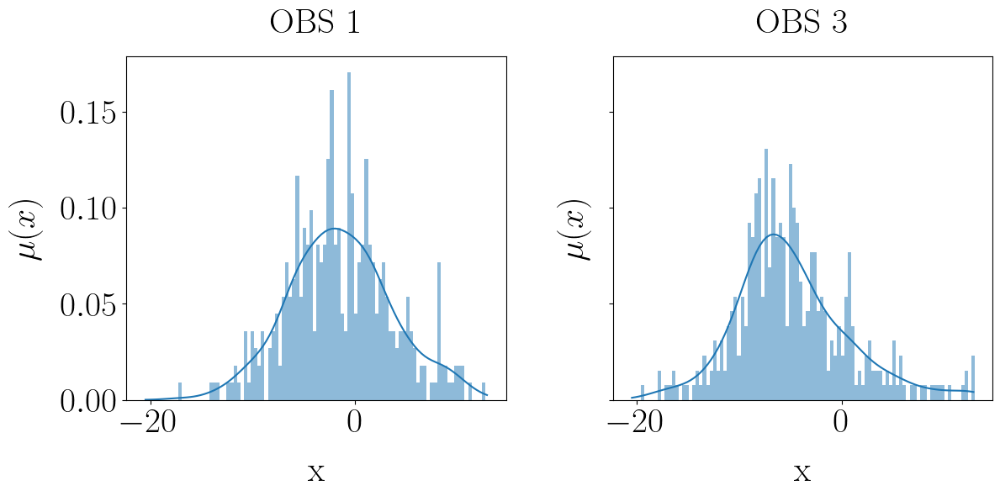

In [51]:
i_rep = 0

mu_i_0 = mu_0[i_rep, :]
mu_i_1 = mu_1[i_rep, :]
hist_i_0 = hist_0[i_rep, :]
hist_i_1 = hist_1[i_rep, :]

# Plot independent distributions
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(12, 6), sharey=True)
ax1, ax2 = axs
ax1.plot(bin_centers, mu_i_0, label=f"OBS {idx_rcv[0]}")
ax1.bar(bin_centers, hist_i_0, width=bin_centers[1] - bin_centers[0], alpha=0.5)
ax2.plot(bin_centers, mu_i_1, label=f"OBS {idx_rcv[1]}")
ax2.bar(bin_centers, hist_i_1, width=bin_centers[1] - bin_centers[0], alpha=0.5)

ax1.set_title(f"OBS {idx_rcv[0]}")
ax2.set_title(f"OBS {idx_rcv[1]}")
# ax1.set_xlabel(r"$\lvert \Pi(f, r) \rvert$")
# ax2.set_xlabel(r"$\lvert \Pi(f, r) \rvert$")
ax1.set_xlabel("x")
ax2.set_xlabel("x")
ax1.set_ylabel(r"$\mu (x)$")
ax2.set_ylabel(r"$\mu (x)$")

Text(0, 0.5, 'y')

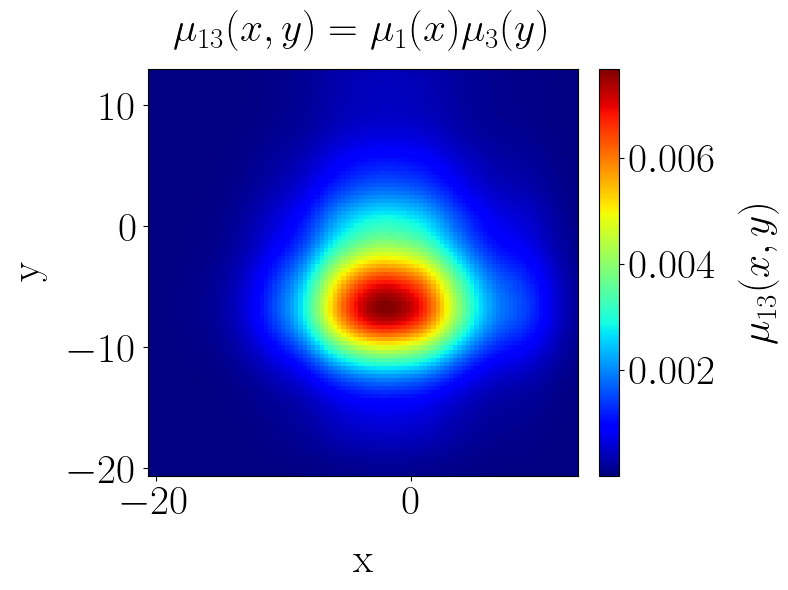

In [52]:
# Build the 2D joint distribution assuming independence (i.e. product of the 1D distributions)
mu_i_0_1 = np.outer(mu_i_0, mu_i_1).T
# Plot joint distribution
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.pcolormesh(bin_centers, bin_centers, mu_i_0_1, shading="auto", cmap="jet")
idx_rcv_couple = f"{idx_rcv[0]}{idx_rcv[1]}"
plt.colorbar(
    im,
    ax=ax,
    label=rf"$\mu_{{{idx_rcv_couple}}}(x, y)$",
)
ax.set_title(
    rf"$\mu_{{{idx_rcv_couple}}}(x, y) = \mu_{{{idx_rcv[0]}}}(x) \mu_{{{idx_rcv[1]}}}(y)$"
)
ax.set_xlabel("x")
ax.set_ylabel("y")

In [53]:
# Build all joint distributions
joint_distribution_mat = np.zeros(
    (len(ds.replica_id), len(bin_centers), len(bin_centers))
)
for i_rep in range(len(ds.replica_id)):
    mu_i_0 = mu_0[i_rep, :]
    mu_i_1 = mu_1[i_rep, :]

    mu_i_0_1 = np.outer(mu_i_0, mu_i_1).T
    joint_distribution_mat[i_rep, :, :] = mu_i_0_1

C:\Users\baptiste.menetrier\AppData\Local\Temp\ipykernel_36844\1713100309.py:11: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig, axs = plt.subplots(


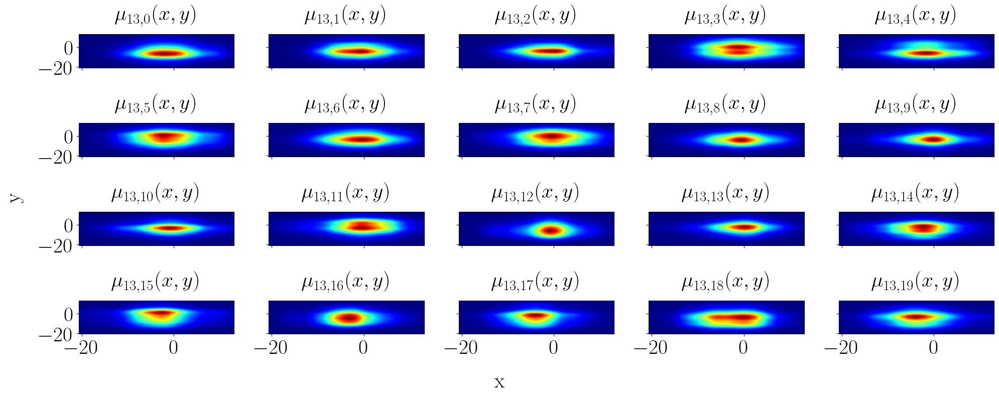

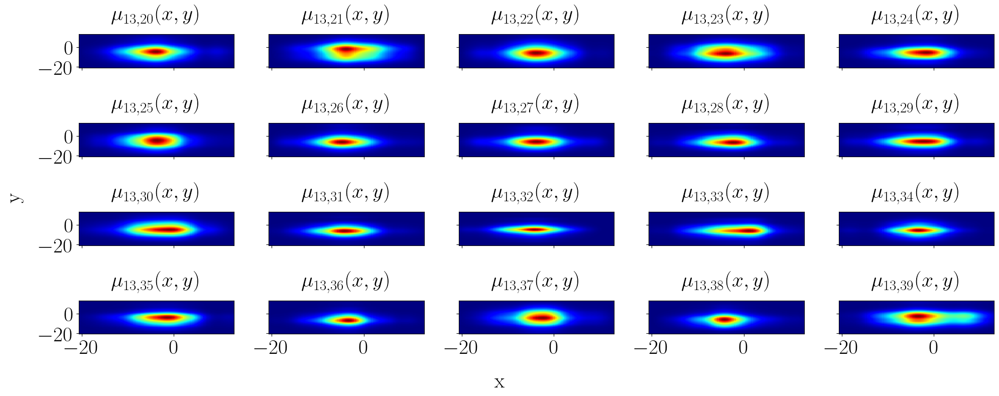

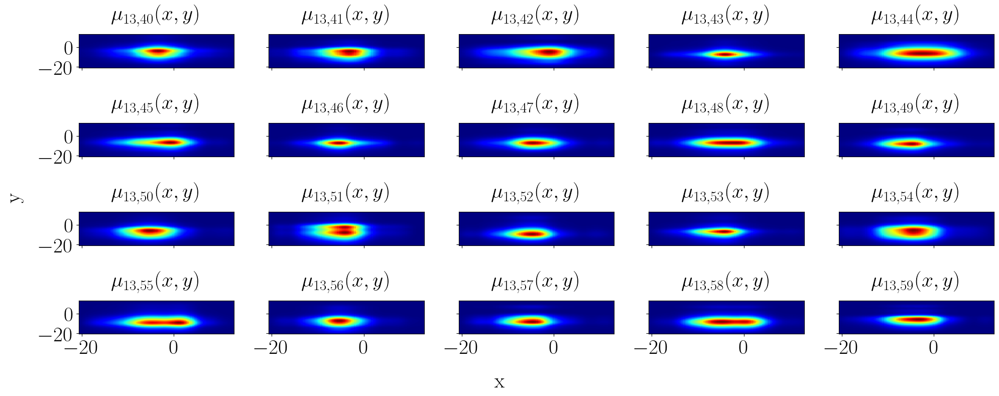

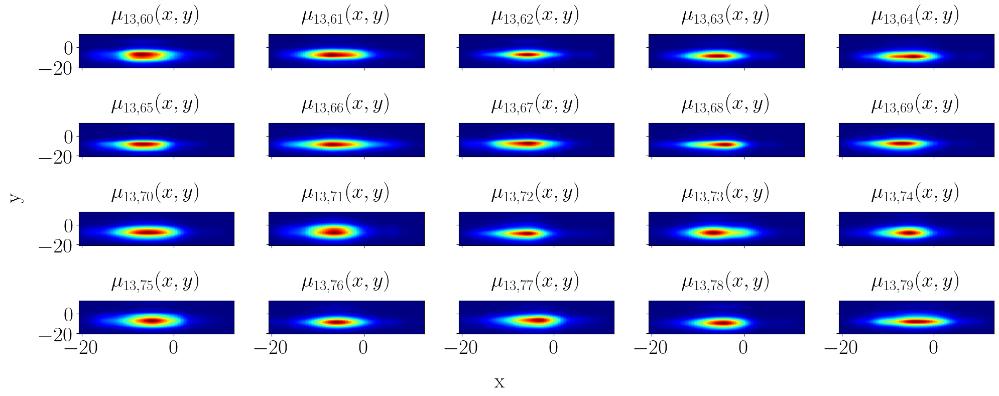

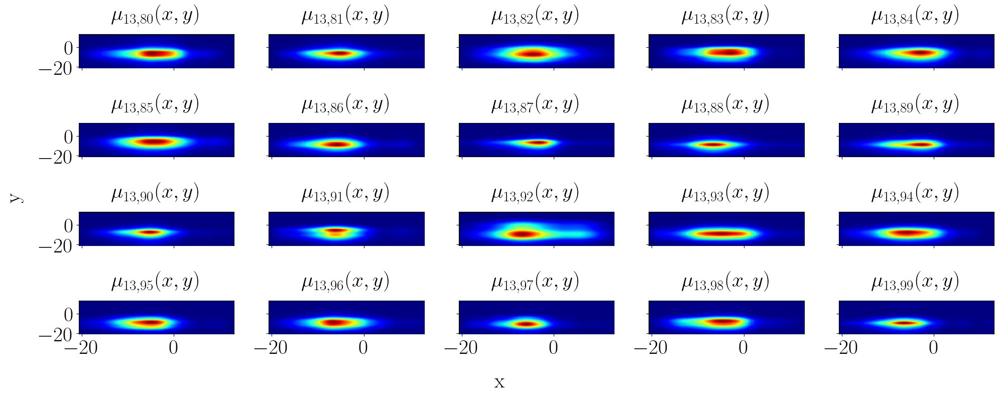

...

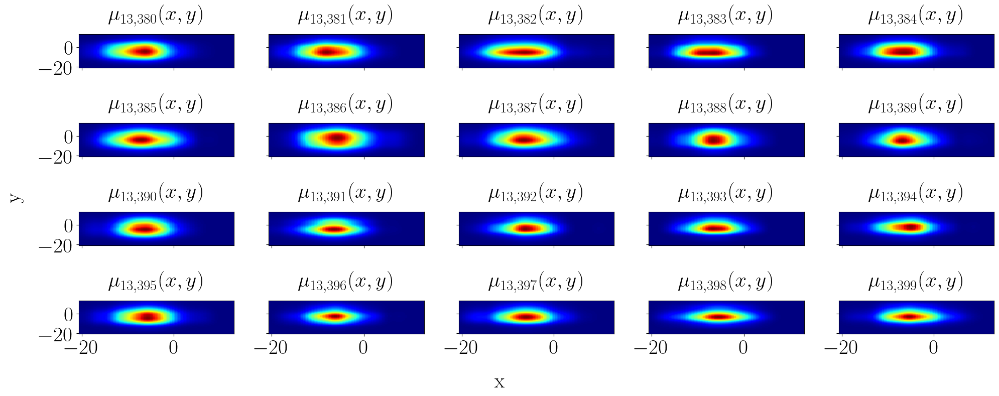

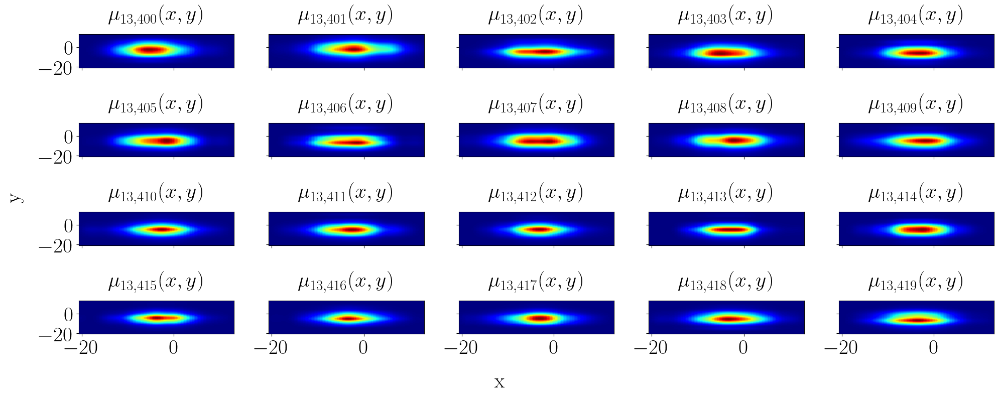

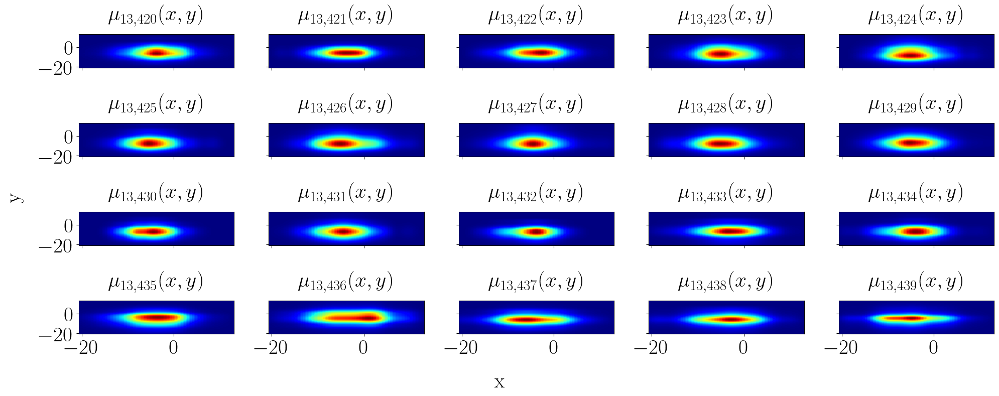

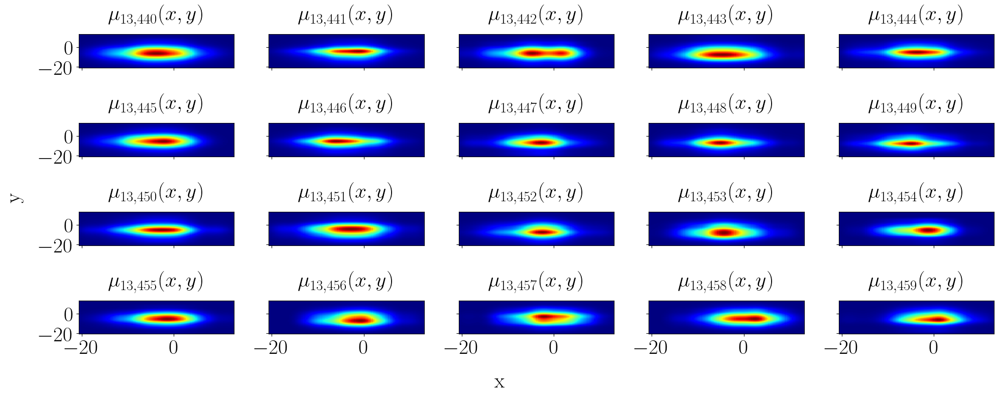

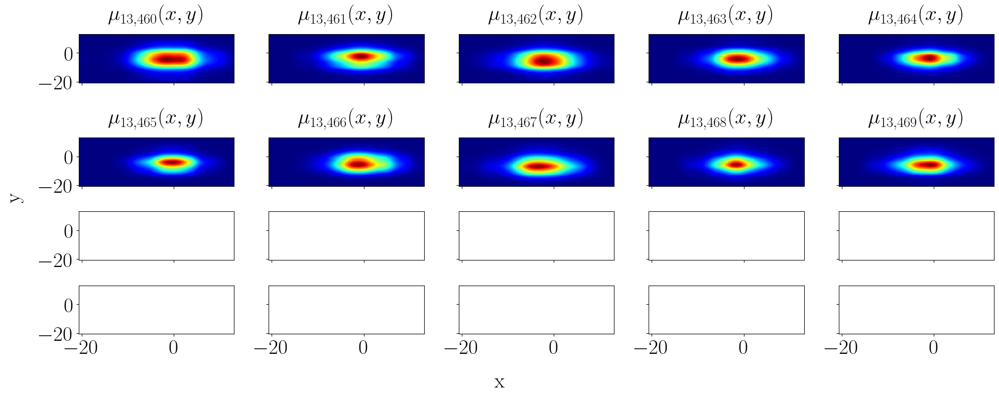

In [54]:
# Plot joint distribution for successives replicas
new_fig_every = 20
n_reps_plot = mu_0.shape[0]

idx_rcv_couple = f"{idx_rcv[0]}{idx_rcv[1]}"

mu_0_1 = []
for i_rep in range(n_reps_plot):

    if i_rep % new_fig_every == 0:
        fig, axs = plt.subplots(
            nrows=4, ncols=5, figsize=(20, 8), sharex=True, sharey=True
        )
        axs = axs.flatten()
        fig.supxlabel("x")
        fig.supylabel("y")

        i_ax = 0

    mu_i_0_1 = joint_distribution_mat[i_rep, ...]

    ax = axs[i_ax]
    im = ax.pcolormesh(bin_centers, bin_centers, mu_i_0_1, shading="auto", cmap="jet")

    dist_2d_label = f"{idx_rcv_couple}, {i_rep}"
    ax.set_title(rf"$\mu_{{{dist_2d_label}}}(x, y)$")
    i_ax += 1
    

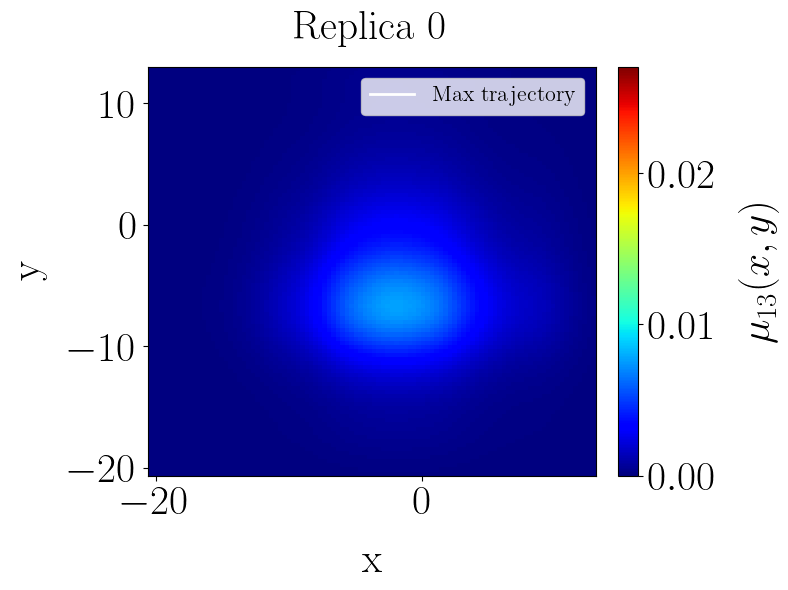

In [56]:
from matplotlib.animation import FuncAnimation

# ------------------------------------------------------------------
# Precompute max indices (efficient)
# ------------------------------------------------------------------

idx_max = np.array(
    [
        np.unravel_index(np.argmax(mu_i, axis=None), mu_i.shape)
        for mu_i in joint_distribution_mat
    ]
)

# Convert to coordinates
x_max = bin_centers[idx_max[:, 1]]
y_max = bin_centers[idx_max[:, 0]]

n_reps = joint_distribution_mat.shape[0]

# ------------------------------------------------------------------
# Figure
# ------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 6))

im = ax.pcolormesh(
    bin_centers,
    bin_centers,
    joint_distribution_mat[0],
    shading="auto",
    cmap="jet",
    vmin=joint_distribution_mat.min(),
    vmax=joint_distribution_mat.max(),
)

cbar = fig.colorbar(im, ax=ax)
cbar.set_label(
    rf"$\mu_{{{idx_rcv_couple}}}(x, y)$"
)

# ax.set_xlabel(r"$|\Pi(f, r)|$ OBS 1")
# ax.set_ylabel(r"$|\Pi(f, r)|$ OBS 2")
ax.set_xlabel("x")
ax.set_ylabel("y")

title = ax.set_title("Replica 0")

# ------------------------------------------------------------------
# Trajectory artists
# ------------------------------------------------------------------

# Line (trajectory)
(line_max,) = ax.plot([], [], "-", color="white", lw=2, label="Max trajectory")

# Current point
(point_max,) = ax.plot([], [], "o", color="red", zorder=5)

ax.legend()

# ------------------------------------------------------------------
# INIT
# ------------------------------------------------------------------


def init():
    im.set_array(joint_distribution_mat[0].ravel())

    line_max.set_data([], [])
    point_max.set_data([], [])

    title.set_text("Replica 0")

    return im, line_max, point_max, title


# ------------------------------------------------------------------
# UPDATE
# ------------------------------------------------------------------


def update(frame):

    # --- update heatmap ---
    data = joint_distribution_mat[frame]
    im.set_array(data.ravel())

    # --- update trajectory ---
    line_max.set_data(x_max[: frame + 1], y_max[: frame + 1])

    # --- current point ---
    point_max.set_data([x_max[frame]], [y_max[frame]])

    # --- title ---
    title.set_text(f"Replica {frame}")

    return im, line_max, point_max, title


# ------------------------------------------------------------------
# Animation
# ------------------------------------------------------------------

ani = FuncAnimation(
    fig,
    update,
    frames=n_reps,
    init_func=init,
    interval=200,
    blit=False,
)

dpi = 100
fps=5
fpath = os.path.join(fig_folder, f"joint_distribution_evolution_{idx_rcv_couple}.mp4")
ani.save(
    fpath,
    writer="ffmpeg",
    fps=fps,
    dpi=dpi,
)

In [57]:

idx_max_mu_0_1 = np.array(
    [
        np.unravel_index(np.argmax(mu_i_0_1, axis=None), mu_i_0_1.shape)
        for mu_i_0_1 in joint_distribution_mat
    ]
)

In [58]:
idx_max_mu_0_1.shape

(470, 2)

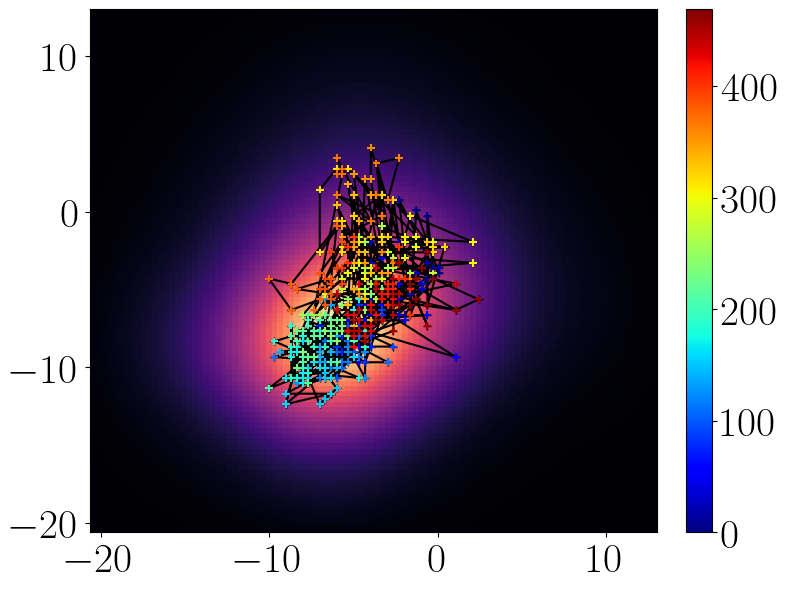

In [59]:
# Plot trajectory of joint distribution in the 2D space (for each replica, plot the point corresponding to the mean of the joint distribution)
fig, ax = plt.subplots(figsize=(8, 6))
cum_mu_0_1 = np.sum(joint_distribution_mat, axis=0)
im = ax.pcolormesh(bin_centers, bin_centers, cum_mu_0_1, shading="auto", cmap="magma")
plt.plot(
    bin_centers[idx_max_mu_0_1[:, 1]],
    bin_centers[idx_max_mu_0_1[:, 0]],
    marker="+",
    color="k",
    # c=np.arange(idx_max_mu_0_1.shape[0]),
)
sc = plt.scatter(bin_centers[idx_max_mu_0_1[:, 1]], bin_centers[idx_max_mu_0_1[:, 0]], marker="+", c=np.arange(idx_max_mu_0_1.shape[0]), s=30, zorder=5, cmap="jet")
plt.colorbar(sc)

### Mesure de distance Wasserstein ordre 1 entre distributions 2D (ie distributions jointes)

In [ ]:
# # Compute Wasserstein distance between joint distributions
# idx_rep_ref = 10
# wasserstein_distances = np.zeros(len(ds.replica_id))

# xx, yy = np.meshgrid(np.arange(bin_centers.size), np.arange(bin_centers.size))
# xx_flat = xx.flatten()
# yy_flat = yy.flatten()
# distribution_support = np.stack(
#     (xx_flat, yy_flat), axis=1
# )  # Both distributions are defined on the same support, so we can use the same distribution_support for both

# mu_ref = joint_distribution_mat[idx_rep_ref, :, :]
# mu_ref_flat = mu_ref.flatten()

# for i_rep in range(len(ds.replica_id)):
#     # We have to reshape the distributions to be 1D arrays of the same size as the distribution_support
#     mu_i_0_1 = joint_distribution_mat[i_rep, :, :]
#     mu_i_0_1_flat = mu_i_0_1.flatten()

#     # wd = wasserstein_distance(
#     #     u_values=distribution_support,
#         # v_values=distribution_support,
#     #     u_weights=mu_i_0_1_flat,
#     #     v_weights=mu_ref_flat,
#     # )
#     u_values=distribution_support
#     v_values=distribution_support
#     u_weights=mu_i_0_1_flat
#     v_weights=mu_ref_flat

#     # print(u_values.shape)
#     # print(v_values.shape)
#     # print(u_weights.shape)
#     # print(v_weights.shape)

#     wd = wasserstein_distance_nd(
#         u_values=u_values,
#         v_values=v_values,
#         u_weights=u_weights,
#         v_weights=v_weights,
#     )

#     # wd = wasserstein_distance_nd(mu_ref, mu_i_0_1)
#     wasserstein_distances[i_rep] = wd

# # # Normalize distances
# wasserstein_distances = (wasserstein_distances - wasserstein_distances.min()) / (
#     wasserstein_distances.max() - wasserstein_distances.min()
# )

In [ ]:
# # Plot wasserstein distances
# fig, ax = plt.subplots(figsize=(8, 6))
# ax.plot(ds.replica_id.values, wasserstein_distances, marker="+")
# ax.set_xlabel("Replica ID")
# ax.set_ylabel("Wasserstein 2D")
# plt.savefig("test")
# # plt.xlim([0, 20])

### Mesure de distance par estimation kde gaussienne bi-variée puis calcul de distance KLD 

Le temps de calcul de la distance de Wassertein d'ordre 1 pour des distributions 2D croit avec la taille du support des distributions (ici les distributions 2D sont de tailles n_bins x n_bins) et explose rapidement. 

On cherche donc une alternative tractable en termes de temps de calcul. Pour se faire on souhaite utiliser la divergence de Kullback-Leibler entre set d'échantillons multivariés. Une implémentation est disponible en ligne et semble être validé par quelques personnes en réponse du post Github. 

La distance KLD est ici définie sur les échantillons des distributions tandisque que l'on manipule les distributions (empirique) jusqu'ici. Pour contourner le problème on procède comme suit

* Pour chaque réplique on estime la densité de probabilité jointe (multi-variée) avec un noyau gaussien (gaussian_kde). 
* On fabrique des échantillons suivant cette distribution jointe estimée (resample). 

Ainsi, pour deux répliques données on peut estimer la distance entre les deux distributions 2D à l'aide de la fonction KLdivergence ci-dessous. 


In [60]:
# From https://gist.github.com/atabakd/ed0f7581f8510c8587bc2f41a094b518 :

# https://mail.python.org/pipermail/scipy-user/2011-May/029521.html

def KLdivergence(x, y):
    """Compute the Kullback-Leibler divergence between two multivariate samples.
      Parameters
      ----------
      x : 2D array (n,d)
        Samples from distribution P, which typically represents the true
        distribution.
      y : 2D array (m,d)
        Samples from distribution Q, which typically represents the approximate
        distribution.
      Returns
      -------
      out : float
        The estimated Kullback-Leibler divergence D(P||Q).
      References
      ----------
      Pérez-Cruz, F. Kullback-Leibler divergence estimation of
    continuous distributions IEEE International Symposium on Information
    Theory, 2008.
    """
    from scipy.spatial import cKDTree as KDTree

    # Check the dimensions are consistent
    x = np.atleast_2d(x)
    y = np.atleast_2d(y)

    n, d = x.shape
    m, dy = y.shape

    assert d == dy

    # Build a KD tree representation of the samples and find the nearest neighbour
    # of each point in x.
    xtree = KDTree(x)
    ytree = KDTree(y)

    # Get the first two nearest neighbours for x, since the closest one is the
    # sample itself.
    r = xtree.query(x, k=2, eps=0.01, p=2)[0][:, 1]
    s = ytree.query(x, k=1, eps=0.01, p=2)[0]

    # There is a mistake in the paper. In Eq. 14, the right side misses a negative sign
    # on the first term of the right hand side.
    return -np.log(r / s).sum() * d / n + np.log(m / (n - 1.0))

# np.random.seed(23)

# dist1 = np.random.multivariate_normal(np.array([1, 1]), np.identity(2), 10000)
# dist2 = np.random.multivariate_normal(np.array([1, 1]), np.identity(2), 10000)

# KLdivergence(dist1, dist2)

# dist1.shape

#### Un exemple 

In [61]:
# Multivariate gaussian kde estimation
idx_rcv = list(log_mod_hist.keys())
rep_0  = 0
# RTF amplitude for rcv 0 and replica 0 (in log scale)
rtf_amp_log_0_0 = 10 * np.log10(ds.rtf_amp.sel(h_index=idx_rcv[0]).isel(replica_id=rep_0).values)

# RTF amplitude for rcv 2 and replica 0 (in log scale)
rtf_amp_log_1_0 = 10 * np.log10(
    ds.rtf_amp.sel(h_index=idx_rcv[1]).isel(replica_id=rep_0).values
)
# RTF amplitude for rcv 0 and replica 1 (in log scale)
rep_1 = 100
rtf_amp_log_0_1 = 10 * np.log10(
    ds.rtf_amp.sel(h_index=idx_rcv[0]).isel(replica_id=rep_1).values
)
# RTF amplitude for rcv 1 and replica 1 (in log scale)
rtf_amp_log_1_1 = 10 * np.log10(
    ds.rtf_amp.sel(h_index=idx_rcv[1]).isel(replica_id=rep_1).values
)

values_pos_0 = np.vstack([rtf_amp_log_0_0, rtf_amp_log_1_0])
values_pos_1 = np.vstack([rtf_amp_log_0_1, rtf_amp_log_1_1])

In [62]:
kernel_pos_0 = gaussian_kde(values_pos_0)
kernel_pos_1 = gaussian_kde(values_pos_1)

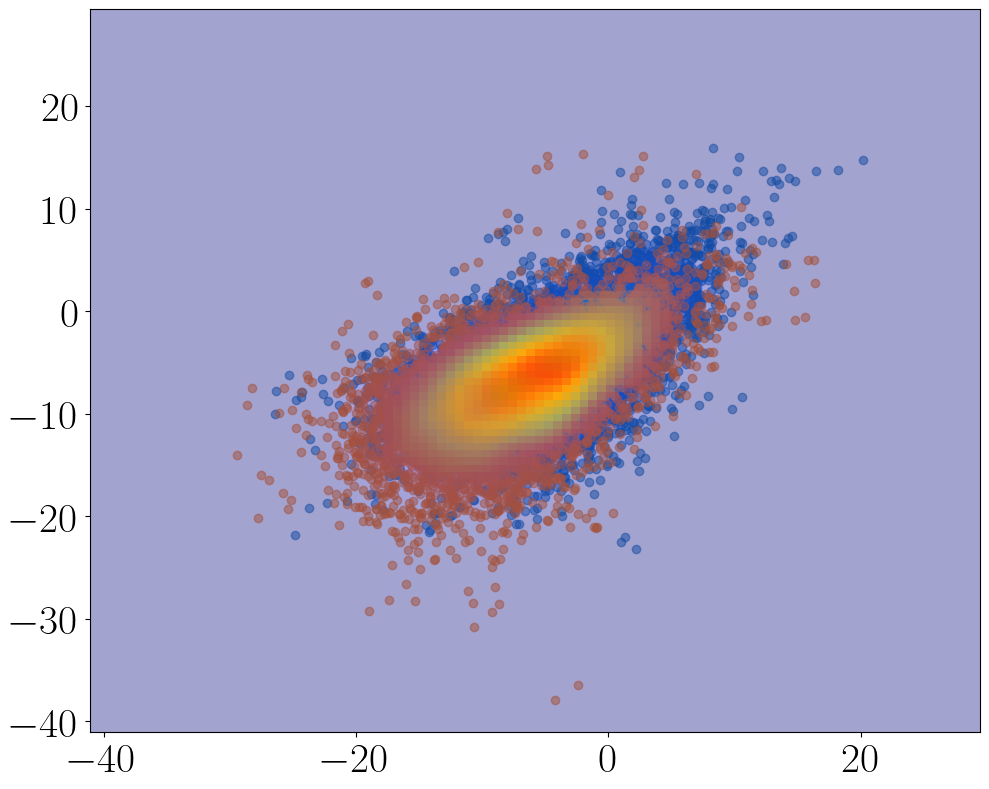

In [63]:
s_size = 10000
sample_pos_0 = kernel_pos_0.resample(s_size).T
sample_pos_1 = kernel_pos_1.resample(s_size).T

min_ = 10 * np.log10(ds.rtf_amp.values).min()
max_ = 10 * np.log10(ds.rtf_amp.values).max()

bin_centers_dense = np.linspace(min_, max_, 100)
X, Y = np.meshgrid(bin_centers_dense, bin_centers_dense)
Z_0 = kernel_pos_0(np.vstack([X.flatten(), Y.flatten()])).reshape(X.shape)
Z_1 = kernel_pos_1(np.vstack([X.flatten(), Y.flatten()])).reshape(X.shape)

plt.figure()
plt.scatter(sample_pos_0[:, 0], sample_pos_0[:, 1], alpha=0.5, label="Replica 0")
plt.scatter(sample_pos_1[:, 0], sample_pos_1[:, 1], alpha=0.5, label="Replica 1")
plt.pcolormesh(X, Y, Z_0, shading="auto", cmap="jet", alpha=0.2)
plt.pcolormesh(X, Y, Z_1, shading="auto", cmap="jet", alpha=0.2)

In [64]:
sample_pos_0.shape

(10000, 2)

In [65]:
KLdivergence(sample_pos_0, sample_pos_1)

np.float64(0.2814349897485583)

#### Mise en pratique 

In [66]:
t0 = time()

idx_rep_ref = 10
sample_size = 5000
idx_rcv = list(log_mod_hist.keys())

# RTF amplitude for rcv 0 and ref replica (in log scale)
rtf_amp_log_0_ref = 10 * np.log10(
    ds.rtf_amp.sel(h_index=idx_rcv[0]).isel(replica_id=idx_rep_ref).values
)
# RTF amplitude for rcv 2 and replica 0 (in log scale)
rtf_amp_log_1_ref = 10 * np.log10(
    ds.rtf_amp.sel(h_index=idx_rcv[1]).isel(replica_id=idx_rep_ref).values
)
values_pos_ref = np.vstack([rtf_amp_log_0_ref, rtf_amp_log_1_ref])


# Multivariate gaussian kde estimation
kernel_pos_ref = gaussian_kde(values_pos_ref)
# Draw samples from the kde
sample_pos_ref = kernel_pos_ref.resample(sample_size).T

kld = []
for i_rep in range(len(ds.replica_id)):
    # RTF amplitude for rcv 0 and replica i (in log scale)
    rtf_amp_log_0_i = 10 * np.log10(
        ds.rtf_amp.sel(h_index=idx_rcv[0]).isel(replica_id=i_rep).values
    )
    # RTF amplitude for rcv 1 and replica i (in log scale)
    rtf_amp_log_1_i = 10 * np.log10(
        ds.rtf_amp.sel(h_index=idx_rcv[1]).isel(replica_id=i_rep).values
    )
    values_pos_i = np.vstack([rtf_amp_log_0_i, rtf_amp_log_1_i])

    # Multivariate gaussian kde estimation
    kernel_pos_i = gaussian_kde(values_pos_i)

    # Draw samples from the kde
    sample_pos_i = kernel_pos_i.resample(sample_size).T

    # Finally compute KL divergence between the reference distribution and the current distribution
    kld_i = KLdivergence(sample_pos_ref, sample_pos_i)
    kld.append(kld_i)

kld = np.array(kld)

print(f"C-Time = {time() - t0:.2f} seconds")

C-Time = 5.28 seconds


Le temps de calcul scale avec le nombre d'échantillons 

In [67]:
print(kld.shape)

(470,)


Text(0, 0.5, 'KL Divergence (2D)')

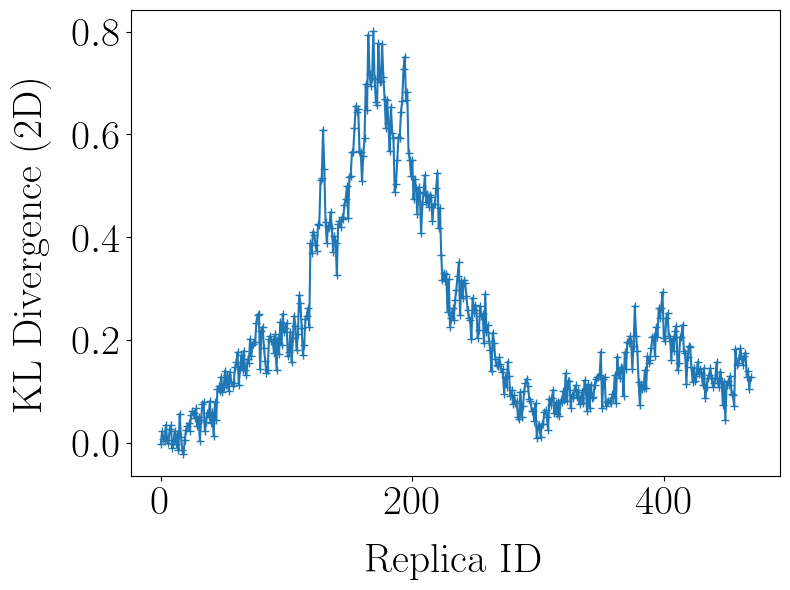

In [68]:
# Plot KL distances
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(ds.replica_id.values, kld, marker="+")
ax.set_xlabel("Replica ID")
ax.set_ylabel("KL Divergence (2D)")
# plt.savefig("test")
# plt.xlim([0, 20])

In [69]:
def get_bootstrap_dist_matrix_joint_distribution_KL_divergence(
    ds, fmin=200, fmax=900, sample_size=10000
):

    # Select frequency range
    ds = ds.sel(f_rtf=slice(fmin, fmax))

    idx_rcv = list(log_mod_hist.keys())

    dist_mat = []
    for idx_rep_ref in range(len(ds.replica_id)):

        # RTF amplitude for rcv 0 and ref replica (in log scale)
        rtf_amp_log_0_ref = 10 * np.log10(
            ds.rtf_amp.sel(h_index=idx_rcv[0]).isel(replica_id=idx_rep_ref).values
        )
        # RTF amplitude for rcv 2 and replica 0 (in log scale)
        rtf_amp_log_1_ref = 10 * np.log10(
            ds.rtf_amp.sel(h_index=idx_rcv[1]).isel(replica_id=idx_rep_ref).values
        )
        values_pos_ref = np.vstack([rtf_amp_log_0_ref, rtf_amp_log_1_ref])

        # Multivariate gaussian kde estimation
        kernel_pos_ref = gaussian_kde(values_pos_ref)
        # Draw samples from the kde
        sample_pos_ref = kernel_pos_ref.resample(sample_size).T

        kld_iref = []
        for i_rep in range(len(ds.replica_id)):
            # RTF amplitude for rcv 0 and replica i (in log scale)
            rtf_amp_log_0_i = 10 * np.log10(
                ds.rtf_amp.sel(h_index=idx_rcv[0]).isel(replica_id=i_rep).values
            )
            # RTF amplitude for rcv 1 and replica i (in log scale)
            rtf_amp_log_1_i = 10 * np.log10(
                ds.rtf_amp.sel(h_index=idx_rcv[1]).isel(replica_id=i_rep).values
            )
            values_pos_i = np.vstack([rtf_amp_log_0_i, rtf_amp_log_1_i])

            # Multivariate gaussian kde estimation
            kernel_pos_i = gaussian_kde(values_pos_i)

            # Draw samples from the kde
            sample_pos_i = kernel_pos_i.resample(sample_size).T

            # Finally compute KL divergence between the reference distribution and the current distribution
            kld_i = KLdivergence(sample_pos_ref, sample_pos_i)
            kld_iref.append(kld_i)

        kld_iref = np.array(kld_iref)

        dist_mat.append(kld_iref)

    dist_mat = np.array(dist_mat)

    # Step 4 : normalize distance matrix to fall into [0, 1] for comparison purpose
    dist_mat = (dist_mat - dist_mat.min()) / (dist_mat.max() - dist_mat.min())

    return dist_mat

In [70]:
dist_mat_KL_fullband = get_bootstrap_dist_matrix_joint_distribution_KL_divergence(
    ds, fmin=fmin, fmax=fmax, sample_size=2000
)

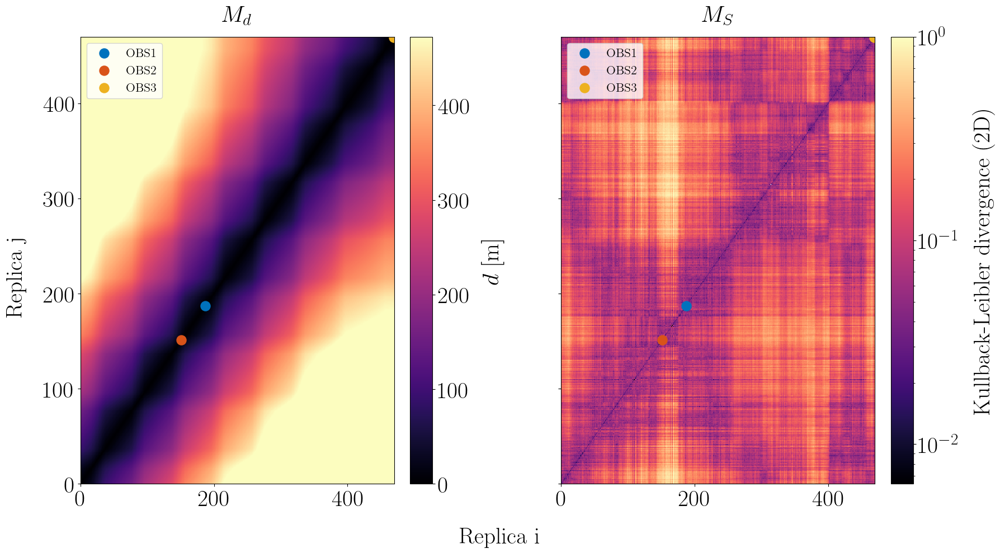

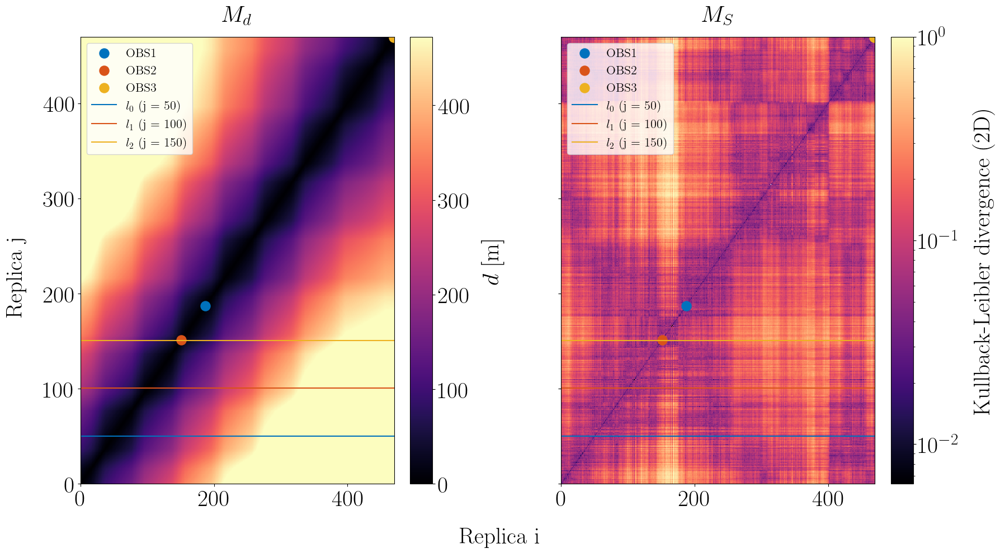

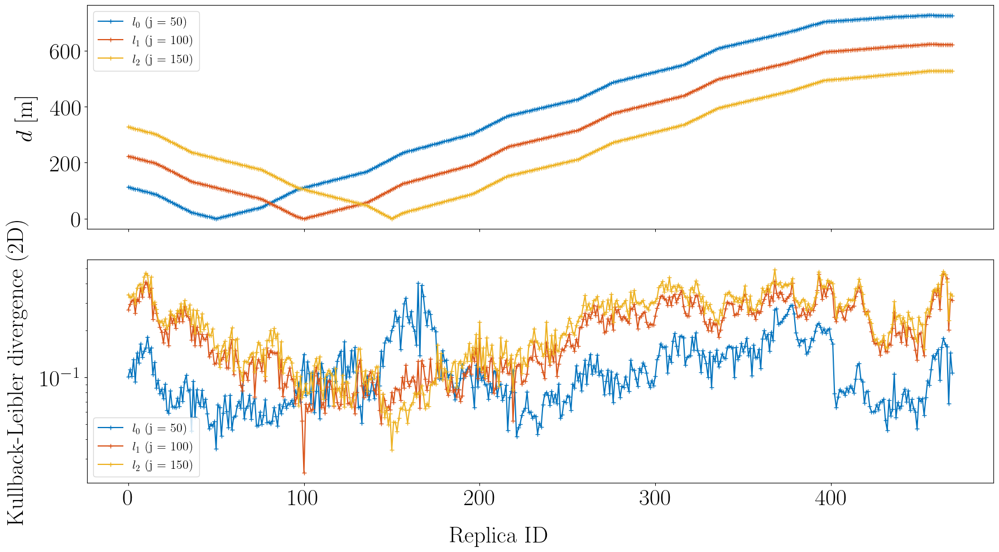

In [71]:
scale = "log"
distance = "KL_divergence_2D"
rcv_combinaison_strategy = "join"

plot_distance_matrix_comparison(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_KL_fullband,
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    scale=scale,
)
selected_lines = [50, 100, 150]
plot_distance_matrix_comparison_line_selected(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_KL_fullband,
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    selected_lines=selected_lines,
    scale=scale,
)
plot_distance_selected_lines(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_KL_fullband,
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    selected_lines=selected_lines,
    scale=scale,
)


Bon, c'est vraiment le gros bazooka, mais ça marche, un peu, mieux que le reste et dans un temps de calcul acceptable : c'est mieux que si c'était pire. 

In [ ]:
ds_subset = ds.copy()
# ds_subset = ds_subset.sel(replica_id=slice(60, 160))

f_bw = (
    100  # bandwidth of the frequency range to consider around the reference frequency
)
fmin = ds.f_rtf.values.min()
fmax = fmin + f_bw

min_freqs = []
max_freqs = []


i = 0
dist_mat_arr = []
while fmin < ds.f_rtf.max():
    print(f"Processing frequency range {fmin:.1f} - {fmax:.1f} Hz")

    dist_mat_KL = get_bootstrap_dist_matrix_joint_distribution_KL_divergence(
        ds_subset, fmin=fmin, fmax=fmax, sample_size=1000
    )

    # if i == 0:
    #     dist_mat = dist_mat_KL
    # else:
    #     dist_mat *= dist_mat_KL
    dist_mat_arr.append(dist_mat_KL)

    # Update frequency range for the next iteration
    min_freqs.append(fmin)
    max_freqs.append(fmax)
    fmin += f_bw
    fmax += f_bw

    i += 1

# Convert lists to arrays
min_freqs = np.array(min_freqs)
max_freqs = np.array(max_freqs)
dist_mat_arr = np.array(dist_mat_arr)

In [ ]:
# Combine 
dist_mat = np.mean(dist_mat_arr, axis=0)

In [ ]:
spatial_dist_mat = build_dist_matrix(ds_subset)

In [ ]:
scale = "log"
distance = "KL_divergence_2D"
rcv_combinaison_strategy = "join"

plot_distance_matrix_comparison(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat,
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    scale=scale,
)
selected_lines = [100, 150, 200, 300]
plot_distance_matrix_comparison_line_selected(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat,
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    selected_lines=selected_lines,
    scale=scale,
)
plot_distance_selected_lines(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat,
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    selected_lines=selected_lines,
    scale=scale,
)

L'approche en sous-bandes de 100 Hz ne semble pas apporter d'amélioration significative. 

### Comparaison à une norme L1 sur la moyenne 

Afin de mieux comprendre quel est l'intérêt d'utiliser les distributions (de manière indépendante ou jointe) par rapport à une grandeur caractéristique de la distribution, par exemple la moyenne. En particulier on souhaite mettre en lumière l'origine des lobes secondaires observés sur la matrice $M$. 

In [ ]:
# Comparaison avec la moyenne


def get_bootstrap_dist_matrix_mean_mod(
    ds, fmin=200, fmax=900
):

    # Select frequency range
    ds = ds.sel(f_rtf=slice(fmin, fmax))

    idx_rcv = list(log_mod_hist.keys())

    dist_mat = []
    for idx_rep_ref in range(len(ds.replica_id)):

        # RTF amplitude for rcv 0 and ref replica (in log scale)
        rtf_amp_log_0_ref = 10 * np.log10(
            ds.rtf_amp.sel(h_index=idx_rcv[0]).isel(replica_id=idx_rep_ref).values
        )
        # RTF amplitude for rcv 2 and replica 0 (in log scale)
        rtf_amp_log_1_ref = 10 * np.log10(
            ds.rtf_amp.sel(h_index=idx_rcv[1]).isel(replica_id=idx_rep_ref).values
        )
        mean_ref = 1 / 2 * (rtf_amp_log_0_ref.mean() + rtf_amp_log_1_ref.mean())

        d_mean_iref = []
        for i_rep in range(len(ds.replica_id)):
            # RTF amplitude for rcv 0 and replica i (in log scale)
            rtf_amp_log_0_i = 10 * np.log10(
                ds.rtf_amp.sel(h_index=idx_rcv[0]).isel(replica_id=i_rep).values
            )
            # RTF amplitude for rcv 1 and replica i (in log scale)
            rtf_amp_log_1_i = 10 * np.log10(
                ds.rtf_amp.sel(h_index=idx_rcv[1]).isel(replica_id=i_rep).values
            )
            mean_i = 1 / 2 * (rtf_amp_log_0_i.mean() + rtf_amp_log_1_i.mean())

            d_mean = np.abs(mean_ref - mean_i)
            d_mean_iref.append(d_mean)

        d_mean_iref = np.array(d_mean_iref)

        dist_mat.append(d_mean_iref)

    dist_mat = np.array(dist_mat)

    # Step 4 : normalize distance matrix to fall into [0, 1] for comparison purpose
    dist_mat = (dist_mat - dist_mat.min()) / (dist_mat.max() - dist_mat.min())

    return dist_mat

In [ ]:
dist_mat_mean = get_bootstrap_dist_matrix_mean_mod(
    ds, fmin=200, fmax=900
)

In [ ]:
scale = "log"
distance = "d_mean_L1"
rcv_combinaison_strategy = "mean"

plot_distance_matrix_comparison(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_mean,
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    scale=scale,
)
selected_lines = [40, 45, 50]
plot_distance_matrix_comparison_line_selected(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_mean,
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    cpa_idx=obs_cpa_idx,
    selected_lines=selected_lines,
    scale=scale,
)
plot_distance_selected_lines(
    spatial_dist_mat=spatial_dist_mat,
    dist_mat=dist_mat_mean,
    fig_folder=fig_folder,
    dist_type=distance,
    rcv_combinaison_strategy=rcv_combinaison_strategy,
    selected_lines=selected_lines,
    scale=scale,
)

Avec cette simple métrique on retrouve un certain nombre de structures présentent pour l'ensemble des méthodes testées :

* Cercle passant par l'OBS 1
* Branches d'hyperbole passant par l'OBS 3

In [ ]:
# # Processing by sub band
# use_kde = False
# n_bins = 100
# idx_rcv_ = [
#     idx for idx in ds.h_index.values if idx != ds.reference_receiver_id
# ]  # All except reference receiver

# idx_rep_ref = 120

# f_bw = 25
# fmin = ds.f_rtf.values.min()
# fmax = fmin + f_bw

# wdist = []
# fmin_wd = []
# fmax_wd = []

# while fmax < ds.f_rtf.max():

#     # Sel frequency band of interest
#     ds_ = ds.sel(f_rtf=slice(fmin, fmax))

#     # Step 1: compute distributions for each receiver
#     log_mod_distribution_dict = {}
#     for id_rcv in idx_rcv_:
#         rtf_amp_rcv = ds_.rtf_amp.sel(h_index=id_rcv)

#         # Compute distribution along traj
#         log_mod_hist_arr, bin_centers, log_mod_kde_arr = get_distribution_arr(
#             rtf_module=rtf_amp_rcv, n_bins=n_bins, kde=use_kde
#         )
#         # Store distribution for current receiver
#         if use_kde:
#             log_mod_distribution_dict[id_rcv] = log_mod_kde_arr
#         else:
#             log_mod_distribution_dict[id_rcv] = log_mod_hist_arr

#     # Build all joint distributions
#     mu_0 = log_mod_distribution_dict[idx_rcv_[0]]  # Distribution of first receiver
#     mu_1 = log_mod_distribution_dict[idx_rcv_[1]]  # Distribution of second receiver

#     joint_distribution_mat = np.zeros(
#         (len(ds.replica_id), len(bin_centers), len(bin_centers))
#     )
#     for i_rep in range(len(ds.replica_id)):
#         mu_i_0 = mu_0[i_rep, :]
#         mu_i_1 = mu_1[i_rep, :]

#         mu_i_0_1 = np.outer(mu_i_0, mu_i_1)
#         joint_distribution_mat[i_rep, :, :] = mu_i_0_1

#     # Compute Wasserstein distance between joint distributions
#     wasserstein_distances = np.zeros(len(ds.replica_id))
#     for i_rep in range(len(ds.replica_id)):
#         mu_i_0_1 = joint_distribution_mat[i_rep, :, :]
#         mu_ref = joint_distribution_mat[idx_rep_ref, :, :]
#         wd = wasserstein_distance_nd(mu_ref, mu_i_0_1)
#         wasserstein_distances[i_rep] = wd

#     # Normalize distances
#     wasserstein_distances = (wasserstein_distances - wasserstein_distances.min()) / (
#         wasserstein_distances.max() - wasserstein_distances.min()
#     )

#     wdist.append(wasserstein_distances)
#     # print(fmin, fmax)
#     fmin_wd.append(fmin)
#     fmax_wd.append(fmax)
#     # print(fmin_wd, fmax_wd)

#     fmin += f_bw
#     fmax += f_bw 

In [ ]:
# fig, ax = plt.subplots(figsize=(8, 6))
# wdist_sum = np.zeros_like(wdist[0])
# wdist_prod = np.ones_like(wdist[0])

# for i_fwd in range(len(wdist)):
#     # Plot wasserstein distances
#     ax.plot(
#         ds.replica_id.values,
#         wdist[i_fwd],
#         color=color(i_fwd),
#         # label=f"{fmin_wd[i_fwd]:.1f} Hz - {fmax_wd[i_fwd]:.1f} Hz",
#     )
#     ax.set_xlabel("Replica ID")
#     ax.set_ylabel("Wasserstein 2D")

#     wdist_sum += wdist[i_fwd]
#     wdist_prod *= 1/(wdist[i_fwd] +1e-12)

# # plt.legend()

# # plt.savefig("test")

# # wdist_prod = (wdist_prod - wdist_prod.min()) / (wdist_prod.max() - wdist_prod.min())
# # wdist_sum = (wdist_sum - wdist_sum.min()) / (wdist_sum.max() - wdist_sum.min())
# wdist_prod = 1 / wdist_prod
# wdist_sum = 1 / len(wdist) * wdist_sum

In [ ]:
# fig, ax = plt.subplots(ncols=2, figsize=(8, 6))
# # Plot wasserstein distances
# ax[0].plot(
#     ds.replica_id.values,
#     wdist_sum,
#     color=color(0),
#     label=f"sum",
#     marker="+"
# )
# ax[0].set_yscale("log")
# ax[1].plot(ds.replica_id.values, wdist_prod, color=color(1), label=f"prod", marker="+")
# ax[1].set_xlabel("Replica ID")
# ax[1].set_ylabel("Wasserstein 2D")
# ax[1].set_yscale("log")
# ax[1].legend()

# # plt.ylim([0, 0.001])

In [ ]:
# def get_bootstrap_dist_matrix_joint_distribution(ds_, fmin=400, fmax=800, n_bins=100, use_kde=False):

#     # Step 1: compute distributions for each receiver
#     idx_rcv_ = [idx for idx in ds_.h_index.values if idx != ds_.reference_receiver_id]        # All except reference receiver

#     # Sel frequency band of interest
#     ds_ = ds_.sel(f_rtf=slice(fmin, fmax))

#     log_mod_distribution_dict = {}
#     for id_rcv in idx_rcv_:
#         rtf_amp_rcv = ds_.rtf_amp.sel(h_index=id_rcv)

#         # Compute distribution along traj
#         log_mod_hist_arr, bin_centers, log_mod_kde_arr = get_distribution_arr(
#             rtf_module=rtf_amp_rcv, n_bins=n_bins, kde=use_kde
#         )
#         # Store distribution for current receiver
#         if use_kde:
#             log_mod_distribution_dict[id_rcv] = log_mod_kde_arr
#         else:
#             log_mod_distribution_dict[id_rcv] = log_mod_hist_arr

#     # Step 2: Build all joint distribution
#     mu_0 = log_mod_distribution_dict[idx_rcv_[0]]     # Distribution of first receiver 
#     mu_1 = log_mod_distribution_dict[idx_rcv_[1]]     # Distribution of second receiver

#     joint_distribution_mat = np.zeros(
#         (len(ds_.replica_id), len(bin_centers), len(bin_centers))
#     )
#     for i_rep in range(len(ds_.replica_id)):
#         mu_i_0 = mu_0[i_rep, :]
#         mu_i_1 = mu_1[i_rep, :]

#         mu_i_0_1 = np.outer(mu_i_0, mu_i_1)
#         joint_distribution_mat[i_rep, :, :] = mu_i_0_1

#     # Step 3: Compute Wasserstein distance between joint distributions
#     dist_mat = []
#     for i, id_ref in enumerate(ds_.replica_id.values): 
#         mu_ref = joint_distribution_mat[id_ref, :, :]
#         wasserstein_distances = np.zeros(len(ds_.replica_id))
#         # t0 = time.time()
#         for i_rep in range(len(ds_.replica_id)):
#             mu_i_0_1 = joint_distribution_mat[i_rep, :, :]
#             wd = wasserstein_distance_nd(mu_ref, mu_i_0_1)
#             wasserstein_distances[i_rep] = wd
#         dist_mat.append(wasserstein_distances)

#         # print(time.time() - t0)

#     dist_mat = np.array(dist_mat)

#     # Step 4 : normalize distance matrix to fall into [0, 1] for comparison purpose
#     dist_mat = (dist_mat - dist_mat.min()) / (dist_mat.max() - dist_mat.min())

#     return dist_mat

In [ ]:
# dist_type = "wasserstein_2d"
# rcv_combinaison_strategy="joint_distribution"

# ds_ = ds
# M_data_joint = get_bootstrap_dist_matrix_joint_distribution(
#     ds_, fmin=400, fmax=800, n_bins=100, use_kde=False
# )

In [ ]:
# plot_distance_matrix_comparison(
#     spatial_dist_mat=spatial_dist_mat,
#     dist_mat=M_data_joint,
#     fig_folder=fig_folder,
#     dist_type=dist_type,
#     rcv_combinaison_strategy=rcv_combinaison_strategy,
#     cpa_idx=obs_cpa_idx,
# )
# selected_lines = [65, 75, 85]
# plot_distance_matrix_comparison_line_selected(
#     spatial_dist_mat=spatial_dist_mat,
#     dist_mat=M_data_joint,
#     fig_folder=fig_folder,
#     dist_type=dist_type,
#     rcv_combinaison_strategy=rcv_combinaison_strategy,
#     cpa_idx=obs_cpa_idx,
#     selected_lines=selected_lines,
# )
# plot_distance_selected_lines(
#     spatial_dist_mat=spatial_dist_mat,
#     dist_mat=M_data_joint,
#     fig_folder=fig_folder,
#     dist_type=dist_type,
#     rcv_combinaison_strategy=rcv_combinaison_strategy,
#     selected_lines=selected_lines,
# )